**Bitácora · Letrozole NMF + PrefixSpan (fused)**

- **v1-v3** `Day1_nmf_v*`, `Day3_prefixspan_v*`  
  Separate Day 1 / Day 3 notebooks (untouched).
- **fused, windowed** `Letrozole_NMF_PrefixSpan_windowed` (2026-10-09) ← **this notebook**  
  Part A = Day 1, Part B = Day 3 (no t-SNE / Table 1, no 3a, no 5a table, no token map). Window: events within 18 months (548 d) before / after ANY letrozole event, merged per patient, exact duplicates dropped.

# Letrozole · NMF bundles and sequence motifs — windowed (+/- 18 months)

**Part A (Day 1)**: events, bag of codes, NMF (k from the stability sweep), loadings, NMF-bundles table, components JSON.  
**Part B (Day 3)**: PrefixSpan motifs per bundle, stability, comparison groups, trajectory graph, final table.

Set `VARIANT`, `WINDOW_MONTHS` and (optionally) `K_OVERRIDE` in the next cell.

In [1]:
VARIANT       = 'win18'      # 'full' = every event of each person | 'win18' = events within 18 months before / after ANY letrozole event
WINDOW_MONTHS = 18        # applied right after tagging (ethos_omop.window_around_anchor)
K_OVERRIDE    = None       # None = the k chosen by the stability sweep; set an int (e.g. 7) to force it
ANCHOR        = 'letrozole'
COHORT        = 'letrozole'
TAG           = f"{COHORT}_{VARIANT}"      # used in every cache / json / xlsx file name


# Part A · Day 1 — NMF bundles

## 0 · Getting the data

**Goal:** pull every letrozole-exposed patient's medical history out of the data warehouse and save it to disk as plain files, so the rest of the notebook runs offline and reproducibly, without hitting Snowflake every time.

`ethos_omop.extract_cohort()` pulls the letrozole-exposure cohort: any patient with a letrozole drug exposure, defined in `sql/letrozole_cohort.sql`. It dumps the same shape `extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both `concept_id` and `source_concept_id` for every domain table, standard-named symlinks for `meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for ontology rollup (drug products to ingredients, unspecified diagnoses to their parents).

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

```python
import ethos_omop as eo
eo.extract_cohort("../../sql/letrozole_cohort.sql")   # -> ../../inputs/letrozole_cohort/
```

The next cell runs this once and skips it on every re-run once `../../inputs/letrozole_cohort/` exists.

**No Snowflake access, or want to see the notebook run against data whose right answer you already know?** Use the synthetic demo extract instead:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through `concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is the whole problem this course is about, and every notebook here works either way.

In [2]:
# One-time export from Snowflake into local CSV files. Safe to re-run: it
# checks OUT_DIR first and skips the (slow) Snowflake pull if the files are
# already there, so you won't accidentally re-download everything every time
# you restart the notebook.
import os
import ethos_omop as eo

OUT_DIR     = "../../inputs/letrozole_cohort/"      # extract_cohort() output, relative to this notebook's dir
COHORT_SQL  = "../../sql/letrozole_cohort.sql"     # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")


../../inputs/letrozole_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


### v2 · Visit pruning (care-driven bias)

The bundles from v1 reflect **care delivery, not condition**: pharmacy, office and ED visits are the
most common tokens and pull unrelated patients together. v2 changes one thing, at the load step
below: every event whose `domain` or `vocabulary_id` is "visit" is dropped before tagging.
Everything after it is unchanged, so v1 and v2 results are directly comparable.

Side effects to expect: the `ed_visit` codeset tag disappears (it sits on visit concepts), the
Table 1 `ed_visit` row reads 0%, and the proxy lookback window can shrink for patients whose first or
last record was a visit. The NMF fit is saved as `nmf_k{k}_letrozole_v2.npz`, so v1's file (which
the Day 3 notebook loads) is not overwritten.


In [3]:
# Load everything from disk into memory as one big table of "events":
# one row per visit / diagnosis / procedure / drug / lab result, for every
# patient in the cohort. `codesets` translates raw medical codes into the
# readable clinical labels (letrozole, breast_cancer, mastectomy, ...) used
# throughout the rest of the notebook.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data


# v2: drop every visit event BEFORE tagging (care-driven bias). A visit row is any row whose
# domain OR vocabulary is "visit"; pharmacy / office / ED visits otherwise dominate the bundles.
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visits   = raw[is_visit]
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level="concept", multi_group=True)

# ---- before / after pruning
tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients:               {raw.person_id.nunique():>10,} -> {events.person_id.nunique():,}")
print(f"distinct concepts:      {raw.concept_id.nunique():>10,} -> {events.concept_id.nunique():,}")
print(f"median events/patient:  {raw.groupby('person_id').size().median():>10,.0f} -> "
      f"{events.groupby('person_id').size().median():,.0f}")
print("\nremoved rows by vocabulary:")
print(visits['vocabulary_id'].value_counts().head(10).to_string())
print("\ntop removed visit concepts:")
print(visits['concept_name'].value_counts().head(10).to_string())

visit_ids = set(visits['concept_id'])
lost      = sorted(t for t, ids in codesets.items() if set(ids) & visit_ids)
print("\ncurated codeset tags that sit on visit concepts (their events are gone):", lost or "none")
vanished  = set(raw['person_id']) - set(events['person_id'])
if vanished:
    print(f"WARNING: {len(vanished):,} patients had only visit events and are no longer in `events`")
if not eo.group_mask(events, 'letrozole').any():
    print("WARNING: the cohort anchor `letrozole` has no events after pruning")
del raw, visits                                      # free memory; `events` is the pruned stream from here on

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events per domain, BEFORE vs AFTER visit pruning
              before    after  removed_%
domain                                  
Condition     458033   458033        0.0
Drug          523552   523552        0.0
Measurement   339167   339167        0.0
Procedure     390455   390455        0.0
Visit         709880        0      100.0
TOTAL        2421087  1711207       29.3

patients:                    5,238 -> 5,238
distinct concepts:          11,008 -> 11,001
median events/patient:         328 -> 215

removed rows by vocabulary:
vocabulary_id
NUCC      516555
Visit     191934
SNOMED      1391

top removed visit concepts:
concept_name
Pharmacy                              516555
Office Visit                          164763
Telehealth                             18916
Home Visit                              8175
Unknown                                 1391
Pharmacy visit                            78
Emergency Room and Inpatient Visit         2

curated codeset tags that sit on visit 

,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
1,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
2,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
3,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
4,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
5,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740


In [4]:
if WINDOW_MONTHS:
    _n0, _p0 = len(events), events.person_id.nunique()
    events = eo.window_around_anchor(events, ANCHOR, months=WINDOW_MONTHS)
    print(f"windowed to +/- {WINDOW_MONTHS} months around any {ANCHOR} event, merged per patient, exact duplicates dropped:")
    print(f"  events   {_n0:,} -> {len(events):,}")
    print(f"  patients {_p0:,} -> {events.person_id.nunique():,}")
    print(f"  median events per patient: {events.groupby('person_id').size().median():.0f}")
else:
    print(f"full variant: every event of each patient ({len(events):,} events, {events.person_id.nunique():,} patients)")


windowed to +/- 18 months around any letrozole event, merged per patient, exact duplicates dropped:
  events   1,711,207 -> 778,644
  patients 5,238 -> 5,238
  median events per patient: 98


In [5]:
# Sanity check: how big is what we just loaded? Useful to know before you
# wait on a slow cell later, and a quick way to notice if an extract came
# back suspiciously empty or huge.
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file   rows    MB
    master_visit_occurrence.csv 886865 111.1
       master_drug_exposure.csv 528746 102.9
           concept_ancestor.csv 488853  10.7
master_condition_occurrence.csv 458040  67.1
master_procedure_occurrence.csv 390673  57.8
         master_measurement.csv 339374  46.1
         master_observation.csv 240551  29.7
                    concept.csv  11793   1.5
                     person.csv   5238   0.7
                      death.csv      0   0.0


## 1 · Four decisions already made for you

**Goal:** flag four judgment calls baked into the data-loading step above, before you trust any number that comes out of it. None of these are bugs — they're modelling choices someone had to make, and you should know what they are.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of diabetes" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    5238.0
mean     1002.0
std       433.0
min         0.0
25%       727.0
50%       977.0
75%      1137.0
max      2588.0


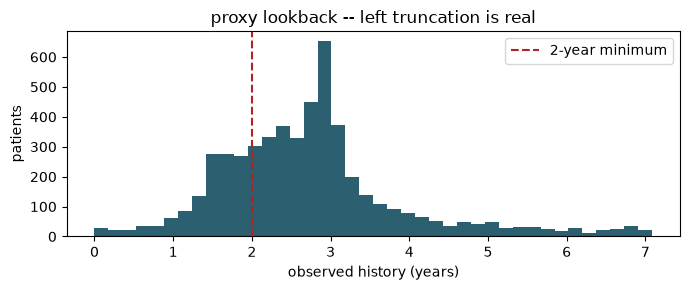


1324 patients (25.3%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [6]:
# How much history do we actually have per patient? (See point 4 above --
# this is the proxy lookback window, not a true observation period.) The
# 2-year line is a common minimum bar for "long enough history to trust an
# absence of a code."
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

**Goal:** show how a clinical concept like "letrozole" turns into an actual, checkable list of medical codes — and why we resolve it by *name* instead of hand-typing code numbers.

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 19022830 means letrozole"), we write down a search pattern ("anything whose name matches 'letrozole' in the RxNorm vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [7]:
# Eyeball it: what did the "letrozole" pattern actually match? One row here
# means one specific product code -- exactly what you want to see before
# trusting anything downstream.
eo.resolve(concept, ['letrozole'], vocabularies=['RxNorm', 'RxNorm Extension'])

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
7978,19022830,letrozole 2.5 MG Oral Tablet,RxNorm,200064,Drug
894,1315947,letrozole 2.5 MG Oral Tablet [Femara],RxNorm,153124,Drug


In [8]:
# Medical coding systems are hierarchical: a drug "ingredient" (letrozole)
# can have several branded/dosed "products" under it, and a diagnosis can
# have several more specific children. `concept_ancestor` lets us walk that
# hierarchy in either direction.

# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
lz = codesets['letrozole']
print("letrozole concepts, direct:      ", len(lz))
print("letrozole concepts, + descendants:", len(eo.expand_descendants(lz)))

# And roll an unspecified diagnosis UP to its parents -- e.g. `breast_cancer`,
# the comorbidity marker that distinguishes this cohort's oncology-indication
# subgroup (letrozole is the anchor here, not breast_cancer -- see Table 1).
bc = codesets['breast_cancer']
print("breast cancer parents, 1 level up:  ", len(eo.roll_up(bc, levels=1)))

letrozole concepts, direct:       2
letrozole concepts, + descendants: 2
breast cancer parents, 1 level up:   1


In [9]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
# What are the most common tags overall, and what fraction of all events
# actually got one of our curated labels versus falling back to a raw name?
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
venipuncture_for_blo__procedure__4102442         21525
letrozole_25_mg_oral__clinical_drug__19022830    18273
progesterone_measure__procedure__4263754         11227
estradiol_total__cpt4__2212320                   10242
gonadotropin_chorion__cpt4__2212631               8693
female_infertility__disorder__201909              7902
transvaginal_echogra__procedure__4027510          6684
psychotherapy_60_min__cpt4__43527905              6505
therapeutic_procedur__cpt4__2314284               5867
luteinizing_hormone___procedure__4287388          5557
progesterone_200_mg___clinical_drug__1552350      5378
manual_therapy_techn__cpt4__2314290               5320
thyroid_stimulating___procedure__4246879          5279
low_back_pain__clinical_finding__194133           5213
ultrasound_pelvic_no__cpt4__2211768               5201

tagged into a codeset: 12.1%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (letrozole, mastectomy, breast_cancer, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

**Goal for this section:** build the simplest possible patient representation — a checklist of which codes each patient has — and then show exactly where it breaks.

In [10]:
# The "bag of codes": one row per patient, one column per code, 1 if the
# patient ever had that code and 0 if not. This throws away *when* things
# happened and *how many times* -- it's the simplest representation there
# is, and the one we're about to show fails.
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :8]

(5238, 2783)


tag,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,036_ml_follitropin_b__quant_branded_drug__43011837,03_ml_enoxaparin_sod__quant_clinical_drug__40160970,03_ml_sarscov2_covid__quant_branded_drug__1735839,03_ml_sarscov2_covid__quant_branded_drug__37355134,03_ml_sarscov2_covid__quant_branded_drug__747830,03_ml_sarscov2_covid__quant_branded_drug__747832
person_id,,,,,,,,
1949,0,0,0,0,0,0,0,0
4358,0,0,0,0,0,0,0,0
4531,0,0,0,0,0,0,0,0
5216,0,0,0,0,0,0,0,0
5294,0,0,0,0,0,0,0,0


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `letrozole` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `letrozole`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

2783 codes, prevalence range 0.019% - 99.847%


,prevalence
tag,
letrozole_25_mg_oral__clinical_drug__19022830,99.8%
venipuncture_for_blo__procedure__4102442,51.5%
thyroid_stimulating___procedure__4246879,38.3%
progesterone_200_mg___clinical_drug__1552350,35.1%
complete_blood_count__procedure__4319466,35.1%
gonadotropin_chorion__cpt4__2212631,34.6%
progesterone_measure__procedure__4263754,33.1%
transvaginal_echogra__procedure__4027510,32.7%
05_ml_choriogonadotr__quant_branded_drug__19127159,32.2%


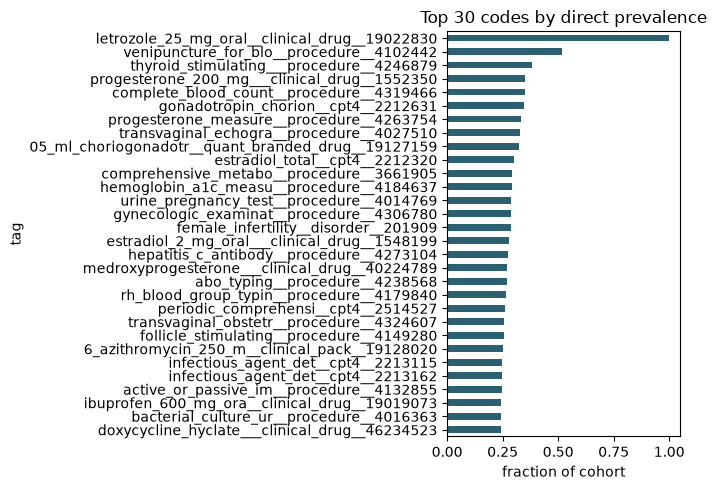

In [11]:
# How common is each code across the whole cohort? (Just column-wise
# averages of the 0/1 matrix above -- no modelling yet.)
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(20).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 30 codes by direct prevalence')
plt.tight_layout(); plt.show()

### Choosing `min_count` from prevalence

`bag_of_codes(min_count=...)` counts **events**, so one patient with 20 refills keeps a code alive. What limits a model is how many **patients** carry a code, so this cell works in patients.

*In plain terms: a code in only a handful of patients can't form a reliable pattern, but dropping too many throws away signal. The table shows what each cutoff costs and suggests one.*

The suggested floor is `ceil(MIN_TRAIN_PATIENTS * cohort / N_TRAIN)`: the patients a code needs so a training split is expected to hold at least `MIN_TRAIN_PATIENTS` of them. It scales with cohort size and is a heuristic, not a test.

,prevalence_%,columns,pairs_kept_%
rule,,,
>= 1 patients,0.0191,9047,100.00
>= 2 patients,0.0382,6330,99.19
>= 5 patients,0.0955,4056,97.35
>= 10 patients,0.1909,2834,94.96
>= 20 patients,0.3818,1949,91.37
>= 35 patients,0.6682,1449,87.49
>= 50 patients,0.9546,1148,83.78
>= 100 patients,1.9091,689,73.99
>= 200 patients,3.8183,389,61.34


cohort 5238 patients, training split 3142
suggested floor: 9 patients (0.172% prevalence) -> 2984 of 9047 columns, 95.4% of patient-code pairs kept
codeset tags below the floor: none


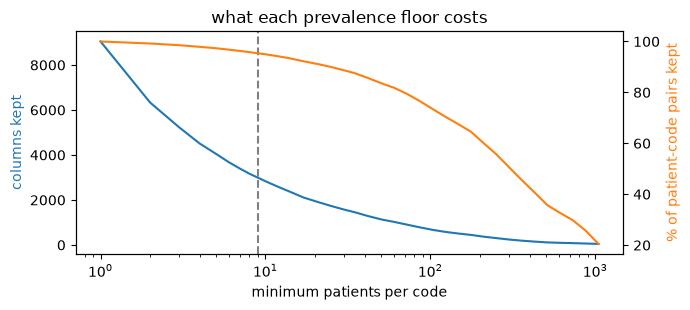


To apply it, build X from the kept codes only (min_count=1 on pre-filtered events):
    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)


In [12]:
import math

MIN_TRAIN_PATIENTS = 5            # a code should appear in >= this many patients of a training split
n_pat   = events.person_id.nunique()
N_TRAIN = min(20_000, int(0.6 * n_pat))      # training-split size used by the k-sweep cells

# patients per code, and events per code (what bag_of_codes' min_count counts)
code, tags = pd.factorize(events['tag'])
key        = events['person_id'].to_numpy(np.int64) * len(tags) + code
prev_pat   = pd.Series(np.bincount(np.unique(key) % len(tags), minlength=len(tags)), index=tags)
ev_cnt     = pd.Series(np.bincount(code, minlength=len(tags)), index=tags)
all_pairs  = int(prev_pat.sum())             # distinct (patient, code) pairs = ones in the full 0/1 matrix

def summarize(mask):
    return {'columns': int(mask.sum()),
            'pairs_kept_%': round(100 * prev_pat[mask].sum() / all_pairs, 2)}

rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), **summarize(prev_pat >= p)}
        for p in [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]]
rows.append({'rule': 'current min_count=20 (events)', 'prevalence_%': np.nan, **summarize(ev_cnt >= 20)})
rule_tbl = pd.DataFrame(rows).set_index('rule')

MIN_PATIENTS = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
KEEP_TAGS    = prev_pat.index[prev_pat >= MIN_PATIENTS]
display(rule_tbl)

# the clinical (codeset) tags are the ones the analysis is about -- do any fall below the floor?
codeset_tags = [t for t in codesets if t in prev_pat.index]
lost = prev_pat[codeset_tags][lambda s: s < MIN_PATIENTS]
print(f"cohort {n_pat} patients, training split {N_TRAIN}")
print(f"suggested floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}% prevalence) -> "
      f"{len(KEEP_TAGS)} of {len(prev_pat)} columns, "
      f"{100 * prev_pat[KEEP_TAGS].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("codeset tags below the floor:", lost.to_dict() if len(lost) else "none")

fig, ax = plt.subplots(figsize=(7, 3.2))
ps = np.unique(np.round(np.geomspace(1, max(2, prev_pat.max() / 5), 40)).astype(int))
ax.plot(ps, [(prev_pat >= p).sum() for p in ps], color='C0')
ax.set_xscale('log'); ax.set_xlabel('minimum patients per code'); ax.set_ylabel('columns kept', color='C0')
ax2 = ax.twinx()
ax2.plot(ps, [100 * prev_pat[prev_pat >= p].sum() / all_pairs for p in ps], color='C1')
ax2.set_ylabel('% of patient-code pairs kept', color='C1')
ax.axvline(MIN_PATIENTS, ls='--', c='grey')
ax.set_title('what each prevalence floor costs')
plt.tight_layout(); plt.show()

print("\nTo apply it, build X from the kept codes only (min_count=1 on pre-filtered events):")
print("    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)")

In [13]:
X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
print(X.shape)

(5238, 2984)


In [14]:
# The punchline of the whole notebook: find one letrozole+breast_cancer
# patient labelled "fertility" and one labelled "oncology" by the rule-based
# check below, then show that the bag-of-codes view (X) can't tell them
# apart at all, even though their real timelines obviously can.
weak = eo.weak_labels(events)                      # rule-based probe labels
lab  = weak.set_index('person_id').weak_label

_eg = events[events.groups.notna()]
Xg = eo.bag_of_codes(_eg.assign(group=_eg.groups.astype(str).str.split('|')).explode('group').reset_index(drop=True), col='group', min_count=1)   # group-level checklist (a concept counts in EVERY group it is in), demo only
both = [p for p in X.index
        if Xg.loc[p].get('letrozole', 0) == 1
        and Xg.loc[p].get('breast_cancer', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'fertility'), None)
b = next((p for p in both if lab[p] == 'oncology'),  None)
assert a and b, ("No identical-bag pair found in this sample. Increase the extract "
                 "size, or inspect `both` to see which side is missing.")

# Same view, plus a few randomly-picked columns where they DO differ -- shown
# side by side so it's clear these two patients aren't identical everywhere,
# just on the two columns that matter for the fertility-vs-oncology question.
diff_cols_all = X.columns[X.loc[a] != X.loc[b]]
diff_cols = list(pd.Index(diff_cols_all).to_series()
                  .sample(n=min(3, len(diff_cols_all)), random_state=0))
print("bag-of-codes view -- identical on letrozole/breast_cancer, "
      f"differs on {diff_cols}:")
display(pd.concat([Xg, X], axis=1).loc[[a, b], ['letrozole', 'breast_cancer'] + diff_cols])

print("\nactual timelines -- obviously different:")
# FOCUS = eo.FERTILITY_TAGS / eo.ONCOLOGY_TAGS -- the same constants
# weak_labels() used to build `lab` -- plus the exposure/anchor tags, so this
# timeline shows the full evidence base behind the label instead of a
# hand-picked subset that can drift from it. Tags that never occurred for a
# given patient simply produce no row below, so this costs nothing visually.
FOCUS = ['letrozole', 'breast_cancer'] + eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS
for pid in (a, b):
    s = events[(events.person_id == pid) & eo.group_mask(events, FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'groups', 'tag']].drop_duplicates('tag').to_string(index=False))

letrozole patients: 5238   labelled: 3681   both-evidence (dropped): 283   no-evidence (dropped): 1274
bag-of-codes view -- identical on letrozole/breast_cancer, differs on ['linaclotide_0145_mg___branded_drug__42900508', 'active_or_passive_im__procedure__4132855', 'trazodone_hydrochlor__clinical_drug__40163460']:


,letrozole,breast_cancer,linaclotide_0145_mg___branded_drug__42900508,active_or_passive_im__procedure__4132855,trazodone_hydrochlor__clinical_drug__40163460
person_id,,,,,
4779438,1,1,0,1,0
264821,1,1,1,0,1



actual timelines -- obviously different:

  person_id 4779438  (fertility)
event_date         groups                                           tag
2019-10-10      letrozole letrozole_25_mg_oral__clinical_drug__19022830
2019-12-13  breast_cancer       primary_malignant_ne__disorder__4162253
2020-12-31 pregnancy_test      urine_pregnancy_test__procedure__4014769

  person_id 264821  (oncology)
event_date         groups                                           tag
2024-07-26 receptor_assay           immunohistochemistry__cpt4__2213300
2024-07-26 receptor_assay      estrogen_receptor_as__procedure__4307360
2024-08-06  breast_cancer       primary_malignant_ne__disorder__4162253
2025-01-28      letrozole letrozole_25_mg_oral__clinical_drug__19022830


**That is the motivation for the whole week.** Identical features, opposite risk. The
information lives in the order, and the representation threw it away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `weak_labels()`

**Goal:** since there's no ground-truth "this patient took letrozole for fertility / for cancer" label in claims data, build a trustworthy *stand-in* label we can use to check our work — and be upfront about how it's built and where it can go wrong.

There are no adjudicated labels in claims data. `weak_labels()` builds probe labels for the
letrozole indication from **corroborating co-evidence only** — clomiphene, gonadotropins and
infertility diagnoses on one side; mastectomy, biopsy, tamoxifen and anastrozole on the
other. Patients with both kinds of evidence, or neither, are dropped, and the counts are
printed so you can see how many.

*In plain terms: instead of guessing the reason for letrozole directly, we look for other, more specific evidence nearby — did the patient also have a fertility drug or an infertility diagnosis? Did they also have a mastectomy or a cancer drug? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time delta is deliberately not used.** If you label by "drug before diagnosis" and
then test whether the time delta predicts the label, you get perfect accuracy by
construction and have learned nothing. These labels are for evaluation, never features.

*In plain terms: it would be tempting to say "letrozole came before the cancer diagnosis, so it must be fertility-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

## 4 · Distance metrics disagree

**Goal:** show that "how similar are two patients" isn't one universal number — the metric you pick changes the answer, and picking the wrong one for claims data quietly breaks everything downstream.

In [15]:
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp

# letrozole is the cohort anchor here -- 100% prevalence (confirmed below), so
# it's a constant column that carries no discriminative signal and would just
# eat a component. Drop it before any distance/SVD/NMF fit; X itself (with
# the column) stays untouched for the two-patient demo above.
# Everything downstream works on a SPARSE copy (Xs): same values as the dense matrix without the
# anchor column, a fraction of the memory, and faster NMF / SVD.
nmf_cols = X.columns[~X.columns.isin(events.loc[eo.group_mask(events, 'letrozole'), 'tag'])]                   # code names for the components
n_pat    = X.shape[0]
Xs = sp.csr_matrix(X.to_numpy())[:, X.columns.get_indexer(nmf_cols)].astype(float).tocsr()
print(f"Xs {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}")

def dist_to_all(row, M, metric, chunk=10_000):
    """Distances from one row to every row of sparse M, densifying only `chunk` rows at a time."""
    return np.concatenate([pairwise_distances(row, M[i:i + chunk].toarray(), metric=metric)[0]
                           for i in range(0, M.shape[0], chunk)])

# First: pick 400 random patients and measure how "far apart" every pair is,
# under two different definitions of distance. If cosine and jaccard disagree
# on how spread out the cohort is, that's a sign the metric matters, not just
# the data.
sub = Xs[:400].toarray()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

# Second: for one specific patient (`a`, our fertility case from the demo
# above), who are their 5 nearest neighbours under each metric, and what
# weak label do those neighbours carry? Also report the direct a<->b
# distance, since b (the oncology case) is exactly the contrast we want.
posa = list(X.index).index(a)
posb = list(X.index).index(b)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = dist_to_all(Xs[posa:posa+1].toarray(), Xs, m)
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")
    print(f"{m:10s} distance({a}, {b}) = {D[posb]:.3f}")

Xs (5238, 2982), density 2.012%
cosine     mean=0.902  sd=0.081
jaccard    mean=0.952  sd=0.045

cosine     neighbours of 4779438: ['fertility', 'fertility', 'fertility', 'fertility', 'fertility']
cosine     distance(4779438, 264821) = 0.898


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    neighbours of 4779438: ['fertility', 'fertility', 'fertility', 'fertility', 'fertility']
jaccard    distance(4779438, 264821) = 0.947


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

**Goal:** show why "just add more codes" eventually backfires — past a certain number of columns, distance stops being meaningful at all.

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [16]:
# Not our data -- pure demonstration. Make random sparse 0/1 tables (2% of
# cells "on", like real code data) of increasing width, and watch the ratio
# of the closest pair's distance to the farthest pair's distance collapse
# toward 1 as width grows. That's the curse of dimensionality happening in
# front of you, independent of anything about breast cancer or letrozole.
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

**Goal:** compress thousands of sparse code columns down into a handful of numbers per patient that are actually usable for distance/clustering/visualization — and see two different ways of doing that compression.

*In plain terms: both methods below take the wide, sparse `X` table (thousands of mostly-zero columns) and produce a much narrower table (a few dozen columns) that still captures most of the real signal. Think of it as automatic summarization of a patient's code history into a small number of "themes." SVD and NMF differ in what kind of themes they're allowed to produce -- that difference is exactly why we look at both.*

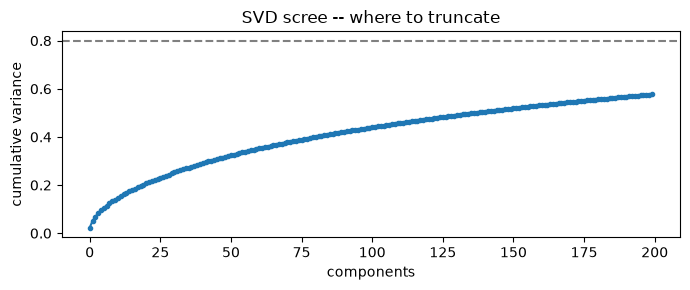

In [17]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

# SVD finds the directions that explain the most variation in the data --
# similar in spirit to PCA. Its components can be positive or negative and
# don't have a clean "these codes belong to this theme" reading, but they're
# a solid general-purpose compression. Normalize first so this lines up with
# the cosine geometry we already decided was the right one for this data.
Xn  = normalize(Xs)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(200, Xs.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

# How many components until we've captured most of the signal? The scree
# plot below answers that -- steep rise then flattening out means most of
# what matters is in the first handful of components.
plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

### Choosing k for the NMF

This sweep puts numbers on the choice of k: held-out error, silhouette, and bootstrap ARI, as Day 2 does for KMeans.

*In plain terms: fit the NMF at several k. For each, check how well it explains unseen patients, how well separated the groups are, and whether the same bundles return on re-draws. Pick the k where extra components stop paying off but the bundles stay reproducible.*

- Every k is fit on the same `N_SWEEP` patients and scored on a disjoint `N_HELD` set.
- Silhouette is computed in the SVD space `Z` that Day 2 used, not in NMF's loading space, which would be circular.
- The sweep repeats on every split in `SPLIT_SEEDS`, each with `N_BOOT_K` bootstrap refits per k. Several splits show whether a k only looks stable because of the patients drawn.
- All fits share `NMF_KW`. They run in parallel on a sparse copy of the matrix, `Xs`.

In [18]:
import time
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 10        # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels (capped)

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
              f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:   18.7s remaining:    3.7s


60 jobs on 12 workers; summed fit time 3.7 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:   20.5s finished


,held_out_err,silhouette,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,,
3,0.890,0.099,0.798,0.025,5,5,0.982,0.0,3
4,0.882,0.105,0.621,0.123,0,3,0.883,0.0,4
5,0.875,0.065,0.703,0.070,2,5,0.976,0.0,5
6,0.870,0.062,0.755,0.052,2,5,0.962,0.0,6
7,0.866,0.072,0.590,0.086,0,2,0.892,0.0,7
8,0.862,0.069,0.633,0.109,1,2,0.908,0.0,8
9,0.858,0.071,0.833,0.037,5,5,0.976,0.0,9
10,0.855,0.068,0.758,0.039,3,5,0.945,0.0,10
11,0.851,0.067,0.812,0.029,5,5,0.963,0.0,11


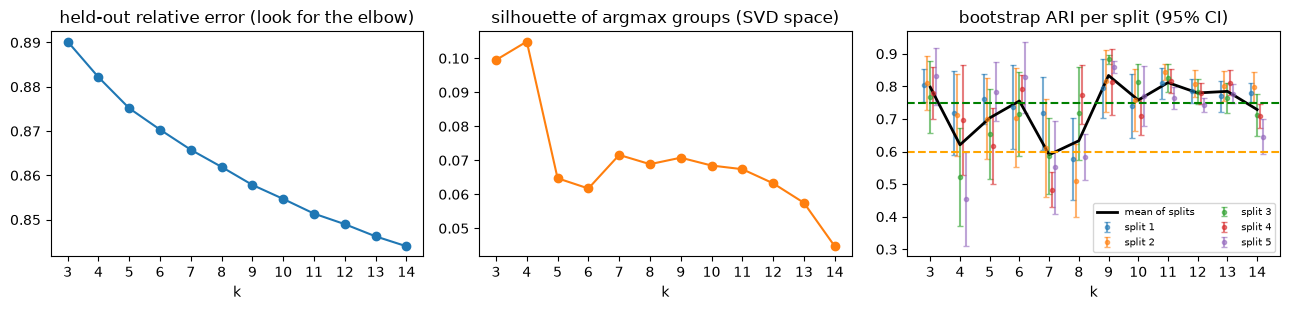

largest k with ARI >= 0.60 on 5+ of 5 splits and mean cos >= 0.75: 14
largest k with ARI >= 0.75 on 5+ of 5 splits and no unstable component (median): 13


In [42]:
import time
import io, contextlib
import os, math
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID      = list(range(3, 15))
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent train / held-out splits of the cohort
N_SWEEP     = min(20_000, int(0.6 * Xs.shape[0]))   # train patients every k is fit on (scales with the cohort)
N_HELD      = min(10_000, Xs.shape[0] - N_SWEEP)    # disjoint held-out patients for error / silhouette
N_BOOT_K    = 10          # bootstrap refits per k and split (reuses nmf_stability above)
NC_SIL      = min(24, Z.shape[1])   # SVD dims Day 2 scored KMeans silhouette in
MIN_SPLITS_OK = math.ceil(1.0 * len(SPLIT_SEEDS))   # a k must pass on this many splits (4 of 5)
N_JOBS      = max(1, (os.cpu_count() or 2) - 2)   # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, Zho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    with contextlib.redirect_stdout(io.StringIO()):          # silence per-boot prints
        cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0],
                                 n_eval=Xtr.shape[0], seed=k)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
            'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho], Z[ho, :NC_SIL]                     # Z rows align with Xs rows

splits  = {s: make_split(s) for s in SPLIT_SEEDS}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(
              delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index()
             for s in SPLIT_SEEDS}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

# one row per k, summarised over splits
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(),
                      'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1')
ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.1, d.ari_mean,
                   yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[2].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[2].axhline(0.75, ls='--', c='green');  ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split (95% CI)'); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_OK) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_OK) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and no unstable component (median):",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Held-out error** always falls with k. Look for the elbow.
- **Silhouette** is low in absolute terms and falls with k. Read the shape.
- **`ari_mean`** is the bootstrap ARI averaged over splits and **`ari_sd_splits`** its spread across splits. **`n_splits_solid`** / **`n_splits_sugg`** count splits with ARI at or above 0.75 / 0.60. **`n_unstable`** is the median over splits.
- Prefer the largest k that is solid on at least 4 of 5 splits (`MIN_SPLITS_OK`). If splits disagree, choose on clinical readability and mark any k below 0.75 as suggestive.
- **`n_used`** counts components that dominate at least 1% of held-out patients. A flat `n_used` means redundant components.
- No single column picks k. Choose after the error elbow and before stability collapses, then confirm the components read as distinct clinical bundles.

### Are those components stable? Bootstrap validation of the NMF

Reading the top codes (above) checks whether a component *means* something. It does not
check whether the component would come back on a different sample of patients. This is the
NMF analogue of Day 2's KMeans bootstrap. It validates the last `nmf` fit above.

*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit resamples patients with replacement (about 63% distinct patients when it draws
  the whole cohort), so this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether a component really is a clinical bundle is
  still the read-the-top-codes judgement above.

In [20]:
int(strong.index.max()) 

13

In [21]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "chemotherapy + antineoplastic drug" reads
# as an actual clinical bundle, not an abstract direction in space. That's
# why we print the top-5 codes per component below: it's how you check
# whether a component actually means something clinically, or is noise.
#
# We fit twice, at k=5 and k=12, to see how the story changes with more
# components allowed (see the annotated discussion two cells down). Each
# component is also sized -- by dominant-component count and % of the
# cohort -- and each top code is shown with its % share of that component's
# total loading, so you can see at a glance both which bundles are large
# populations and which codes actually drive each one.
# for k in [3, 5, 8, 12]:
for k in [K_OVERRIDE or int(strong.index.max())]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xs)
    H   = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab_k = nmf.transform(Xs).argmax(axis=1)
    dom = pd.Series(lab_k).value_counts().sort_index()
    # save the fit for reuse (Day 3 loads it instead of refitting); the tag keeps cohorts apart
    np.savez(f"nmf_k{k}_{TAG}.npz", H=H.to_numpy(), cols=np.array(H.columns, dtype=str),
             pids=X.index.to_numpy(), labels=lab_k)
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / n_pat * 100:.1f}%): {codes}")


NMF with 13 components:
component 0 (n=396, 7.6%): ['catheterization_and___cpt4__2110199 (4.3%)', 'estradiol_total__cpt4__2212320 (4.0%)', 'gonadotropin_chorion__cpt4__2212631 (3.7%)', 'progesterone_measure__procedure__4263754 (3.6%)', 'transvaginal_echogra__procedure__4027510 (3.4%)', 'follicle_stimulating__procedure__4149280 (3.4%)', 'female_infertility__disorder__201909 (3.2%)', 'luteinizing_hormone___procedure__4287388 (3.2%)', 'hysterosalpingograph__cpt4__2211565 (3.1%)', 'ocular_prosthetic_se__procedure__4049310 (3.1%)']
component 1 (n=747, 14.3%): ['estradiol_2_mg_oral___clinical_drug__1548199 (4.8%)', 'progesterone_50_mgml__clinical_drug__1552382 (4.2%)', 'follicle_stimulating__branded_drug__19128370 (3.6%)', 'leuprolide_acetate_5__clinical_drug__1351622 (3.3%)', '05_ml_ganirelix_acet__quant_clinical_drug__40162447 (3.2%)', 'progesterone_200_mg___clinical_drug__1552350 (3.1%)', '05_ml_choriogonadotr__quant_branded_drug__19127159 (3.0%)', 'chorionic_gonadotrop__branded_drug__40

### Reading the output

**Goal:** check whether these automatically-found components actually mean something clinically, or are just statistical noise — you do that by reading the top-5-codes list per component and asking "does this look like a real clinical group?"


*In plain terms: no deep learning, no neural network -- just three lines of matrix math, and it already recovered groups that make clinical sense (a fertility-medication bundle, a preconception genetic-screening bundle, a pregnancy-outcome bundle). Worth remembering next time someone asks "why not jump straight to a fancy model?"*

### Where do the clinical codes sit? (loadings check)

The top-5 lists can hide a code that matters but is never in a top 5. This cell takes the fertility and oncology evidence tags that `weak_labels()` uses, plus every other codeset, and shows how each code's total loading splits across the components. Each row sums to 100%.

*In plain terms: for each hand-defined clinical code, which bundle owns it, and is it concentrated in one bundle or spread thin?*

`owner` is the component with the largest share. `rank_in_owner` is the code's rank inside that component (1 = its top code). A high share with a rank in the hundreds means the code attaches to the bundle but does not define it. Only codes with a codeset tag appear.

In [22]:
K_CHECK = nmf.n_components_      # the last fit above
H8 = pd.DataFrame(nmf.components_, columns=nmf_cols)
# v3: columns of H8 are concept tokens; a codeset's loading is the SUM over the tokens it groups (a token counts in EVERY codeset it is in)
H8g = eo.group_loadings(H8, events)

# watch list comes from codesets.yaml (via eo), not hand-typed; the cohort anchor is excluded
WATCH = {
    'fertility':      eo.FERTILITY_TAGS,
    'oncology':       eo.ONCOLOGY_TAGS,
    'other codesets': [t for t in eo.CODESETS
                       if t not in eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS and t != 'letrozole'],
}

rows, missing = [], []
for group, tags in WATCH.items():
    for tag in tags:
        if tag not in H8g.columns or H8g[tag].sum() == 0:
            missing.append(tag); continue
        share = H8g[tag] / H8g[tag].sum() * 100                       # this code's split across components
        own   = int(share.values.argmax())
        rows.append({'group': group, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K_CHECK)},
                     'owner': own, 'rank_in_owner': int((H8.iloc[own] > H8.iloc[own][H8.columns.intersection(list(eo.group_tokens(events, tag)))].max()).sum() + 1)})

loadings = pd.DataFrame(rows).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K_CHECK)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(
        axis=1, cmap='Blues', subset=comp_cols))
print("components (n, top code):",
      {i: (int((nmf.transform(Xs).argmax(1) == i).sum()), H8.iloc[i].idxmax()[:28]) for i in range(K_CHECK)})
print("codeset tags with no column (dropped by the prevalence floor, or never occur):", missing or "none")

components (n, top code): {0: (396, 'catheterization_and___cpt4__'), 1: (747, 'estradiol_2_mg_oral___clinic'), 2: (1263, 'amoxicillin_875_mg_c__clinic'), 3: (541, 'single_live_birth_fr__clinic'), 4: (221, 'cftr_cystic_fibrosis__cpt4__'), 5: (258, 'fentanyl_005_mgml_in__brande'), 6: (327, 'abo_typing__procedure__42385'), 7: (199, 'vitamin_d_25hydroxy___proced'), 8: (290, 'therapeutic_procedur__cpt4__'), 9: (443, 'periodic_comprehensi__cpt4__'), 10: (236, 'oocyte_recovery__procedure__'), 11: (151, 'infectious_agent_det__cpt4__'), 12: (166, 'urinalysis_by_dip_st__cpt4__')}
codeset tags with no column (dropped by the prevalence floor, or never occur): ['breast_biopsy', 'antineoplastic_drug', 'metastasis', 'dcis', 'ed_visit']


base fit: NMF k=13  (the `nmf` from the cell above)
  boot 1/10  1s  ARI 0.632
  boot 2/10  1s  ARI 0.897
  boot 3/10  0s  ARI 0.733
  boot 4/10  0s  ARI 0.899
  boot 5/10  1s  ARI 0.831
  boot 6/10  0s  ARI 0.846
  boot 7/10  0s  ARI 0.872
  boot 8/10  1s  ARI 0.869
  boot 9/10  0s  ARI 0.875
  boot 10/10  1s  ARI 0.820


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,396,"catheterization_and___cpt4__2110199, estradiol...",0.995,0.002,0.988,solid
1,747,"estradiol_2_mg_oral___clinical_drug__1548199, ...",0.988,0.025,0.913,solid
2,1263,"amoxicillin_875_mg_c__clinical_drug__19115197,...",0.987,0.012,0.959,solid
3,541,single_live_birth_fr__clinical_finding__401429...,0.994,0.001,0.991,solid
4,221,"cftr_cystic_fibrosis__cpt4__42742292, hexa_hex...",0.996,0.001,0.994,solid
5,258,"fentanyl_005_mgml_in__branded_drug__35603455, ...",0.962,0.063,0.773,solid
6,327,"abo_typing__procedure__4238568, rh_blood_group...",0.986,0.021,0.926,solid
7,199,"vitamin_d_25hydroxy___procedure__4007831, t4_f...",0.986,0.004,0.979,solid
8,290,"therapeutic_procedur__cpt4__2314284, manual_th...",0.989,0.002,0.984,solid
9,443,"periodic_comprehensi__cpt4__2514527, gynecolog...",0.981,0.013,0.945,solid



bootstrap ARI of argmax labels: mean 0.827  sd 0.080  (Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)


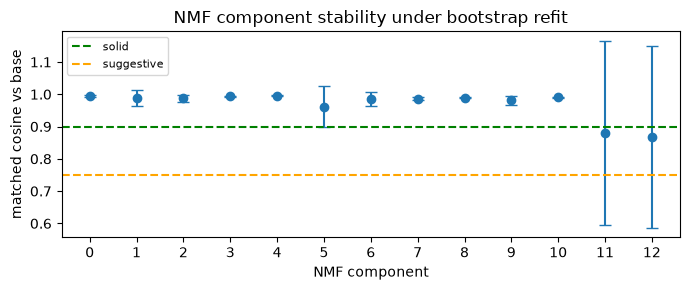

In [23]:
print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
cos, ari = nmf_stability(nmf, Xs)

dom_n = pd.Series(nmf.transform(Xs).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=nmf_cols)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

**NMF bundles as a table** — one row per component for the underwriter review: n (%), the top-5 OMOP entities (name, vocabulary + code, concept_id, share of the bundle's patients) and two empty columns to fill in (pathway, UW suggestion). Written to `nmf_components_<cohort>_k<k>_v3.xlsx`. `RANK_BY = 'prevalence'` ranks by how many of the bundle's patients have the code instead of by NMF loading.

In [24]:
COHORT = 'letrozole'
# Export the NMF components as a table to review with the underwriters: one row per bundle, the last two columns are left empty to fill in.
import re
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

RANK_BY = 'loading'        # 'loading' = codes that define the bundle (NMF loading); 'prevalence' = codes most patients of the bundle have
TOP_N   = 5
k_exp   = nmf.n_components_
XLSX_NMF = f"nmf_components_{COHORT}_k{k_exp}_{VARIANT}.xlsx"

lab_e  = nmf.transform(Xs).argmax(1)                                   # dominant component per patient (same rule as the sizes above)
Hc     = pd.DataFrame(nmf.components_, columns=nmf_cols)
meta   = events.drop_duplicates('tag').set_index('tag')

def entity(tok, prev):
    r = meta.loc[tok]
    name = re.split(r' \(|;| This ', str(r.concept_name))[0].strip()
    name = name if len(name) >= 8 else str(r.concept_name)          # packs like '{6 (azithromycin ...) } Pack [Z-PAK]' would be cut to '{6'
    name = name if len(name) <= 60 else name[:60].rsplit(' ', 1)[0] + '…'
    return f"{name} [{r.vocabulary_id} {r.concept_code}] (concept_id {int(r.concept_id)}; {prev:.0%} of bundle)"

rows_e = []
for c in range(k_exp):
    members = np.flatnonzero(lab_e == c)
    prev  = pd.Series(np.asarray(Xs[members].mean(axis=0)).ravel(), index=nmf_cols)     # share of the bundle's patients with each code
    score = Hc.iloc[c] if RANK_BY == 'loading' else prev
    top   = score.nlargest(TOP_N).index
    rows_e.append({'Group': f"c{c}",
                   'n (%)': f"{len(members):,} ({len(members) / len(lab_e):.1%})",
                   'Most frequently OMOP clinical entities found': "\n".join(f"{i}. {entity(t, prev[t])}" for i, t in enumerate(top, 1)),
                   'Suggested Clinical Pathway': '',
                   'UW suggestion': ''})
nmf_table = pd.DataFrame(rows_e)

F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'NMF k={k_exp}'
ws.append(list(nmf_table.columns))
for j in range(1, ws.max_column + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 30
for row in nmf_table.itertuples(index=False):
    ws.append(list(row))
for i in range(2, len(nmf_table) + 2):
    ws.row_dimensions[i].height = 15 * TOP_N + 6
    for j in range(1, ws.max_column + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='center' if j in (1, 2) else 'left')
for j, w in enumerate([14, 16, 95, 40, 40], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
ws.cell(len(nmf_table) + 3, 1, f"Source: Day 1 v3 {COHORT}, NMF k={k_exp} on concept-level tokens ({len(lab_e):,} patients). n (%) = patients whose dominant component is the bundle. "
        f"Entities ranked by {'NMF loading in the bundle' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; "
        "the percentage is the share of the bundle's patients with that code. The last two columns are left empty on purpose.").font = F(italic=True)
wb.save(XLSX_NMF)
print(f"wrote {os.path.abspath(XLSX_NMF)} ({k_exp} bundles)")
nmf_table


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/nmf_components_letrozole_k13_win18.xlsx (13 bundles)


,Group,n (%),Most frequently OMOP clinical entities found,Suggested Clinical Pathway,UW suggestion
0,c0,396 (7.6%),1. Catheterization and introduction of saline ...,,
1,c1,747 (14.3%),1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,,
2,c2,"1,263 (24.1%)",1. amoxicillin 875 MG / clavulanate 125 MG Ora...,,
3,c3,541 (10.3%),1. Single live birth from singleton pregnancy ...,,
4,c4,221 (4.2%),1. CFTR (cystic fibrosis transmembrane conduct...,,
5,c5,258 (4.9%),1. fentanyl 0.05 MG/ML Injection [Sublimaze] [...,,
6,c6,327 (6.2%),1. ABO typing [SNOMED 91315004] (concept_id 42...,,
7,c7,199 (3.8%),"1. Vitamin D, 25-hydroxy measurement [SNOMED 1...",,
8,c8,290 (5.5%),"1. Therapeutic procedure, 1 or more areas, eac...",,
9,c9,443 (8.5%),1. Periodic comprehensive preventive medicine ...,,


In [25]:
COHORT = 'letrozole'
# Persist the NMF components next to the .npz: n, top tokens with concept ids, a signature, and the names you give them.
# Part B of this notebook loads this file (COMP_JSON) for the component names. Workflow: run once -> copy the printed DESCR block
# (or paste names from Claude) into DESCR below -> run again. Components not listed in DESCR keep the names already saved
# in the file, as long as their top-5 tokens are unchanged.
import json, hashlib, os
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
DESCR = {}      # windowed run: names are not carried over from the full run; fill this after reading the printed top tokens

k_j       = nmf.n_components_
NPZ_J     = f"nmf_k{k_j}_{TAG}.npz"
JSON_PATH = f"nmf_k{k_j}_{TAG}_components.json"
TOP_J     = 10

Hj     = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab_j  = nmf.transform(Xs).argmax(1)
meta_j = events.drop_duplicates('tag').set_index('tag')
old    = json.load(open(JSON_PATH))['components'] if os.path.exists(JSON_PATH) else {}

comps = {}
for c in range(k_j):
    row = Hj.iloc[c]
    sig = list(row.nlargest(5).index)
    toks = []
    for t, v in row.nlargest(TOP_J).items():
        m = meta_j.loc[t]
        toks.append(dict(token=t, concept_id=int(m.concept_id) if pd.notna(m.concept_id) else None,
                         concept_name=str(m.concept_name), vocabulary_id=str(m.vocabulary_id), concept_code=str(m.concept_code),
                         loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
    n    = int((lab_j == c).sum())
    keep = old.get(str(c), {})
    keep = keep if set(keep.get('signature', [])) == set(sig) else {}            # saved names only survive if the component is unchanged
    d    = DESCR.get(c, {})
    comps[str(c)] = dict(n=n, pct=round(n / len(lab_j) * 100, 2), signature=sig,
                         name=d.get('name', keep.get('name')), group=d.get('group', keep.get('group')),
                         status=d.get('status', keep.get('status')), top_tokens=toks)

out = dict(cohort=COHORT, k=int(k_j), npz=NPZ_J,
           npz_sha256=hashlib.sha256(open(NPZ_J, 'rb').read()).hexdigest() if os.path.exists(NPZ_J) else None,
           n_patients=int(len(lab_j)), components=comps)
with open(JSON_PATH, 'w') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"saved {JSON_PATH}  (k={k_j}, {len(lab_j):,} patients)\n")

print(f"{'comp':>4} {'n':>6} {'%':>5}  name  |  top tokens")
for c, d in comps.items():
    print(f"{c:>4} {d['n']:>6} {d['pct']:5.1f}  {d['name'] or '(unnamed)'}  |  " + ', '.join(t['token'].split('__')[0] for t in d['top_tokens'][:4]))
print("\n# paste-ready DESCR (edit name / group / status, then re-run this cell):")
print("DESCR = {")
for c, d in comps.items():
    extra = f", status={d['status']!r}" if d['status'] else ''
    print(f"    {c}: dict(name={d['name']!r}, group={d['group']!r}{extra}),")
print("}")


saved nmf_k13_letrozole_win18_components.json  (k=13, 5,238 patients)

comp      n     %  name  |  top tokens
   0    396   7.6  (unnamed)  |  catheterization_and, estradiol_total, gonadotropin_chorion, progesterone_measure
   1    747  14.3  (unnamed)  |  estradiol_2_mg_oral, progesterone_50_mgml, follicle_stimulating, leuprolide_acetate_5
   2   1263  24.1  (unnamed)  |  amoxicillin_875_mg_c, ibuprofen_800_mg_ora, 6_azithromycin_250_m, fluconazole_150_mg_o
   3    541  10.3  (unnamed)  |  single_live_birth_fr, ultrasound_pregnant, postnatal_maternal_e, glucose_measurement
   4    221   4.2  (unnamed)  |  cftr_cystic_fibrosis, hexa_hexosaminidase, ikbkap_inhibitor_of, fmr1_fragile_x_messe
   5    258   4.9  (unnamed)  |  fentanyl_005_mgml_in, propofol_injection, ondansetron_injectio, level_iv_surgical_pa
   6    327   6.2  (unnamed)  |  abo_typing, rh_blood_group_typin, serologic_test_for_r, rbc_antibody_detecti
   7    199   3.8  (unnamed)  |  vitamin_d_25hydroxy, t4_free_measurement

# Part B · Day 3 — sequence motifs inside the NMF bundles

## Mini Table 1 · letrozole cohort by confirmed breast-cancer diagnosis

**Confirmed breast cancer** = a patient with *any* condition row matching **ICD-9 174.x**, **ICD-10 C50.x** or
**SNOMED concept 4162253** (primary malignant neoplasm of breast). Everyone else is "no breast cancer dx".
The extract keeps standard concepts only, so ICD codes are not in `concept.csv`; they are read from the raw
`condition_source_value` column, which `load_events()` drops. The `breast_cancer` tag used elsewhere in this notebook
is the narrower, name-matched codeset, so the two counts differ (see the "meets" rows).

In [26]:
cond = pd.read_csv(os.path.join(OUT_DIR, 'master_condition_occurrence.csv'),
                   usecols=['person_id', 'condition_concept_id', 'condition_source_value', 'condition_start_date'],
                   dtype={'condition_source_value': str}, parse_dates=['condition_start_date'])
src  = cond.condition_source_value.fillna('').str.upper().str.replace('.', '', regex=False)   # 'C50.911' -> 'C50911'
crit = {'ICD-9 174.x':     src.str.startswith('174'),
        'ICD-10 C50.x':    src.str.startswith('C50'),
        'SNOMED 4162253':  cond.condition_concept_id.eq(4162253)}

cohort_ids = set(events.person_id)
case_mask  = np.logical_or.reduce(list(crit.values()))
case_ids   = set(cond.person_id[case_mask]) & cohort_ids
groups = {'Overall': cohort_ids,
          'No breast cancer dx': cohort_ids - case_ids,
          'Confirmed breast cancer dx': case_ids}

lz        = eo.index_dates(events, 'letrozole').set_index('person_id')['index_date']
age_yrs   = (lz - person.set_index('person_id')['birth_date'].reindex(lz.index)).dt.days / 365.25
female    = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
first_dx  = cond[case_mask].groupby('person_id').condition_start_date.min()       # first confirmed dx per patient
crit_ids  = {k: set(cond.person_id[m]) & cohort_ids for k, m in crit.items()}

# diagnosis-related rows: curated codesets whose events are conditions
ev_c      = events[events.group.notna()]
tag_dom   = ev_c.assign(g=ev_c.groups.astype(str).str.split('|')).explode('g').groupby('g').domain.agg(lambda s: s.mode().iat[0])
DX_TAGS   = sorted(tag_dom.index[tag_dom == 'Condition'])
has       = {t: set(ev_c.loc[eo.group_mask(ev_c, t), 'person_id']) for t in DX_TAGS}

def describe(name, ids):
    n   = len(ids)
    npc = lambda k: f"{k} ({k / n:.1%})" if n else "0"
    a   = age_yrs.reindex(list(ids))
    row = {'N (% of cohort)': f"{n} ({n / len(cohort_ids):.1%})",
           'Age at first letrozole, mean (SD)': f"{a.mean():.1f} ({a.std():.1f})" if n else '-',
           'Female, n (%)': npc(len(ids & female))}
    for k, s in crit_ids.items():
        row[f'Meets {k}, n (%)'] = npc(len(ids & s))
    before = [first_dx.get(p) is not None and first_dx[p] < lz[p] for p in ids]
    row['Dx recorded before first letrozole, n (%)'] = npc(sum(before)) if name == 'Confirmed breast cancer dx' else '-'
    for t in DX_TAGS:
        row[f'{t}, n (%)'] = npc(len(ids & has[t]))
    return row

table1 = pd.DataFrame({name: describe(name, ids) for name, ids in groups.items()})
display(table1)
print("curated diagnosis codesets shown:", DX_TAGS)

,Overall,No breast cancer dx,Confirmed breast cancer dx
N (% of cohort),5238 (100.0%),5168 (98.7%),70 (1.3%)
"Age at first letrozole, mean (SD)",35.2 (6.9),34.9 (6.6),51.8 (8.2)
"Female, n (%)",5238 (100.0%),5168 (100.0%),70 (100.0%)
"Meets ICD-9 174.x, n (%)",0 (0.0%),0 (0.0%),0 (0.0%)
"Meets ICD-10 C50.x, n (%)",70 (1.3%),0 (0.0%),70 (100.0%)
"Meets SNOMED 4162253, n (%)",49 (0.9%),0 (0.0%),49 (70.0%)
"Dx recorded before first letrozole, n (%)",-,-,43 (61.4%)
"breast_cancer, n (%)",44 (0.8%),0 (0.0%),44 (62.9%)
"dcis, n (%)",16 (0.3%),4 (0.1%),12 (17.1%)
"infertility, n (%)",1806 (34.5%),1804 (34.9%),2 (2.9%)


curated diagnosis codesets shown: ['breast_cancer', 'dcis', 'infertility', 'menopause_status', 'pcos', 'pregnancy_outcome', 't2dm']


In [27]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
oseltamivir_75_mg_or__clinical_drug__1799141 -> letrozole_25_mg_oral__clinical_drug__19022830 -> venipuncture_for_blo__procedure__4102442 -> drug_tests_presumpti__cpt4__42628602 -> urinalysis_by_dip_st__cpt4__2212168 -> infectious_agent_ant__cpt4__2213087 -> infectious_agent_det__cpt4__2213115 -> infectious_agent_det__cpt4__2213162 -> bacterial_culture_ur__procedure__4016363 -> blood_cell_count_aut__procedure__4035541 -> rh_blood_group_typin__procedure__4179840 -> syphilis_test_qualit__procedure__4218428

median sequence length: 93


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** In v1 pharmacy visits were the most common
   tokens (`pharmacy__visit__38004338`) and made every motif list a chain of pharmacy / office
   visits. Dropping them removes that care-setting bias. Visit-borne signal is invisible here by
   construction (Day 1 v2 found no curated tag sitting on a visit concept, so no codeset tag is lost).

## 1 · PrefixSpan, implemented

In [28]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **NMF components of
`Day1_nmf_v3`** (k=7 on concept-level tokens, visits pruned).

What the v2 components look like (top codes and the Day 1 v2 fertility / oncology cross-tab):

- **Fertility, four bundles:** treatment c2 (gonadotropins, GnRH agonist, ART), carrier screening c4,
  prenatal labs c7 (ABO / Rh), pregnancy outcome c0.
- **Oncology, one bundle: c5.** Its top codes are peri-operative (ondansetron / ketorolac injectables,
  fentanyl, propofol), but it holds 62% of the breast-cancer-only patients. It is small, so read it as a lower bound.
- **Background, c1, c3, c6:** acute-infection pharmacy (antibiotics, steroids, NSAIDs), preventive
  labs (lipids, HbA1c, TSH, vitamin D), therapeutic / manual procedures (PT, chiropractic).
  Without visit tokens c1 is no longer "pharmacy visits" but the drugs themselves.

Day 3 asks what order those codes come in, per component. The draft triage (needs underwriter
review) is printed next to each component below.

In [29]:
# Part B starts from the NMF fitted in Part A (same events, same prevalence floor, same anchor drop): no refit, no cache file.
K    = nmf.n_components_
H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab  = pd.Series(nmf.transform(Xs).argmax(1), index=X.index)
comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# DRAFT triage labels -- need underwriter review.
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
COMP = {}                                                     # auto-names from the top tokens; real names come from the components JSON below
for c in range(K):
    top = H.iloc[c].idxmax()
    COMP[c] = (top[:20], f'c{c}: ' + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]), BG, UNCLEAR)
# Names from the components JSON written by the last cell of Part A: override COMP for every component whose top-5 tokens still match
# (>= 4 of 5); otherwise the auto-name is kept and a warning is printed. Point COMP_JSON at another file to reuse it.
import json
COMP_JSON = f"nmf_k{K}_{TAG}_components.json"
if os.path.exists(COMP_JSON):
    J = json.load(open(COMP_JSON))['components']
    for c in range(K):
        j = J.get(str(c))
        if not j or not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in {COMP_JSON} differ from this NMF, its name is ignored")
            continue
        COMP[c] = (COMP[c][0], j['name'], j.get('group') or COMP[c][2]) + ((j.get('status') or COMP[c][3],) if len(COMP[c]) > 3 else ())
    print(f"component names loaded from {COMP_JSON}")
else:
    print(f"{COMP_JSON} not found: components are auto-named (name them in DESCR in the last cell of Part A)")
print("top tokens per component:")
for c in range(K):
    print(f"  c{c}:", ', '.join(H.iloc[c].nlargest(4).index.str.slice(0, 32)))

print(f"{'comp':>4} {'n':>6} {'%':>5}  {'group':<24} name")
for c, v in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>6} {n / len(comp) * 100:5.1f}  {v[2]:<24} {v[1]}")


component names loaded from nmf_k13_letrozole_win18_components.json
top tokens per component:
  c0: catheterization_and___cpt4__2110, estradiol_total__cpt4__2212320, gonadotropin_chorion__cpt4__2212, progesterone_measure__procedure_
  c1: estradiol_2_mg_oral___clinical_d, progesterone_50_mgml__clinical_d, follicle_stimulating__branded_dr, leuprolide_acetate_5__clinical_d
  c2: amoxicillin_875_mg_c__clinical_d, ibuprofen_800_mg_ora__clinical_d, 6_azithromycin_250_m__clinical_p, fluconazole_150_mg_o__clinical_d
  c3: single_live_birth_fr__clinical_f, ultrasound_pregnant___cpt4__2211, postnatal_maternal_e__procedure_, glucose_measurement___procedure_
  c4: cftr_cystic_fibrosis__cpt4__4274, hexa_hexosaminidase___cpt4__4274, ikbkap_inhibitor_of___cpt4__4274, fmr1_fragile_x_messe__cpt4__4274
  c5: fentanyl_005_mgml_in__branded_dr, propofol_injection__clinical_dru, ondansetron_injectio__clinical_d, level_iv_surgical_pa__cpt4__2213
  c6: abo_typing__procedure__4238568, rh_blood_group_typin__pr

In [30]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.15, max_cand=100, n_out=1500, seed=0, n_jobs=None):
    """All components in parallel (they are independent), like Day 1's k-sweep."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    jobs = []
    for c in COMP:
        idx_in  = np.flatnonzero(comp == c)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(COMP, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 5% components entirely
motifs = component_motifs()
for c, (_, name, grp, triage) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{grp}]: {name}  (n={(comp == c).sum()})")
    print(f"      draft triage: {triage}")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  2 out of 13 | elapsed:    0.9s remaining:    4.8s
[Parallel(n_jobs=12)]: Done  5 out of 13 | elapsed:    2.3s remaining:    3.7s
[Parallel(n_jobs=12)]: Done  8 out of 13 | elapsed:    8.2s remaining:    5.1s
[Parallel(n_jobs=12)]: Done 11 out of 13 | elapsed:   21.4s remaining:    3.9s



===== component 0 [background]: c0: catheterization_and, estradiol_total, gonadotropin_chorion  (n=396)
      draft triage: routine, indication unclear (use other evidence)


[Parallel(n_jobs=12)]: Done 13 out of 13 | elapsed:  1.4min finished


,pattern,sup_in,sup_out,lift
0,catheterization_and___cpt4__2110199 -> hystero...,0.462,0.104,4.1
1,transvaginal_echogra__procedure__4027510 -> es...,0.417,0.101,3.9
2,venipuncture_for_blo__procedure__4102442 -> ca...,0.442,0.110,3.8
3,catheterization_and___cpt4__2110199 -> letrozo...,0.422,0.107,3.7



===== component 1 [background]: c1: estradiol_2_mg_oral, progesterone_50_mgml, follicle_stimulating  (n=747)
      draft triage: routine, indication unclear (use other evidence)


...

,pattern,sup_in,sup_out,lift
0,oocyte_recovery__procedure__4072862 -> culture...,0.860,0.009,46.6
1,estradiol_total__cpt4__2212320 -> oocyte_recov...,0.826,0.009,44.8
2,estradiol_total__cpt4__2212320 -> oocyte_recov...,0.873,0.010,44.1
3,venipuncture_for_blo__procedure__4102442 -> oo...,0.818,0.009,42.8



===== component 11 [background]: c11: infectious_agent_det, infectious_agent_det, cytopathology_cervic  (n=151)
      draft triage: routine, indication unclear (use other evidence)


,pattern,sup_in,sup_out,lift
0,cytopathology_cervic__cpt4__2213244 -> infecti...,0.285,0.036,6.4
1,cytopathology_cervic__cpt4__2213244 -> infecti...,0.285,0.036,6.4
2,cytopathology_cervic__cpt4__2213244 -> infecti...,0.285,0.037,6.3
3,infectious_agent_det__cpt4__2213115 -> infecti...,0.477,0.067,6.3



===== component 12 [background]: c12: urinalysis_by_dip_st, complete_blood_count, comprehensive_metabo  (n=166)
      draft triage: routine, indication unclear (use other evidence)


,pattern,sup_in,sup_out,lift
0,urinalysis_by_dip_st__cpt4__2212166 -> triacyl...,0.404,0.018,14.8
1,therapeutic_prophyla__cpt4__2314215 -> therape...,0.404,0.021,13.5
2,comprehensive_metabo__procedure__3661905 -> tr...,0.446,0.033,10.7
3,therapeutic_prophyla__cpt4__2314215 -> compreh...,0.404,0.029,10.7


Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c5** read as a cancer-treatment path (workup -> surgery / chemo -> endocrine drug)? Without
  visits, the peri-operative injectables carry the "surgery happened" step on their own.
- Do the fertility bundles (c0, c2, c4, c7) read as distinct stages — screening, stimulation, pregnancy,
  prenatal labs — rather than one blob?
- Do the background bundles (c1, c3, c6) stay generic, or reveal a hidden indication now that the
  pharmacy-visit chains are gone?

### A second lens: the Day 1 fertility / oncology probe

`weak_labels()` gives a direct, rule-based split of the indication, built from corroborating
co-evidence only. It is a probe, not the structure: it labels only part of the cohort, and
oncology is tiny next to fertility (see the counts printed below), so the eight components
above are the primary view and this is a cross-check.

Caveat: the probe labels come from `FERTILITY_TAGS` / `ONCOLOGY_TAGS`, so a motif made of those
same tags partly rediscovers the label rule. Read the motifs that *add* something around them.

In [31]:
weak = eo.weak_labels(events)
wl   = weak.set_index('person_id').weak_label

# Every patient here has letrozole by cohort construction, so no filtering needed. Still use
# LOCAL mining: a global 4% threshold is tuned for the full mixed cohort, and the smaller
# indication subgroup would be buried under it.
y_lz = np.array([wl.get(p, 'unlabelled') for p in pids])
print("letrozole patients:", len(db),
      "  labelled:", int((y_lz != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_lz, return_counts=True))))

pats_lz = prefixspan(db, max(3, int(0.08 * len(db))), max_len=4)
C_lz = [tuple(p) for p in pats_lz[pats_lz.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['fertility', 'oncology']:
    print(f"\n=== {g} indication")
    display(discriminative(y_lz == g, C_lz, sequences_db=db, min_in=0.10).head(4))

letrozole patients: 5238   labelled: 3681   both-evidence (dropped): 283   no-evidence (dropped): 1274
letrozole patients: 5238   labelled: 3681    {np.str_('fertility'): np.int64(3619), np.str_('oncology'): np.int64(62), np.str_('unlabelled'): np.int64(1557)}

=== fertility indication


,pattern,sup_in,sup_out,lift
0,venipuncture_for_blo__procedure__4102442 -> pr...,0.316,0.096,3.1
1,venipuncture_for_blo__procedure__4102442 -> ve...,0.308,0.094,3.1
2,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.277,0.086,3.0
3,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.280,0.086,3.0



=== oncology indication


,pattern,sup_in,sup_out,lift
0,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.532,0.253,2.1
1,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.677,0.396,1.7
2,venipuncture_for_blo__procedure__4102442 -> le...,0.371,0.249,1.5
3,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.290,0.217,1.3


## 2b · Are the motifs stable?

Section 2 mined each component **once**, on one fixed sample, so every `lift` above is a single number.
Day 1 asked the same question of the NMF (`nmf_stability`, five split seeds, "solid on 4+ of 5"). Same idea here,
two tiers, because there are two different questions:

1. **Bootstrap — is the *lift number* steady?** Resample the component's patients (and the outside sample) with
   replacement 1,000 times and recompute `sup_in`, `sup_out`, `lift` for the same candidate motifs. Gives a 95%
   range for lift. Cheap: no re-mining.
2. **Split seeds — would the *motif itself* be found again?** Split each component's patients 50 / 50 at random.
   Mine on one half, score on the held-out half, repeat for 5 seeds. A motif counts as **replicated** in a split if
   it is nominated on the train half **and** still reaches the support floor and `lift >= MIN_LIFT` on the
   held-out half. Different seeds can nominate different candidates, so this also tests the candidate step.

```
 component's patients ──┬─ bootstrap x1000 (same candidates)  ->  lift_lo ... lift_hi
                        └─ split seed s=1..5:  [ train half | held-out half ]
                                                 mine here     score here    ->  splits_found (0-5)
```

Verdict, same words as Day 1: **solid** = replicated in 4+ of 5 splits and `lift_lo >= MIN_LIFT`;
**suggestive** = 3 of 5; otherwise **unstable**.

In [32]:
import collections, time

MIN_LIFT      = 2                       # a motif must be at least this specific to its component
MIN_SPLITS_OK = 4                       # of the 5 split seeds, as in Day 1
REL_SUP, N_OUT, SEED = 0.15, 1500, 0    # the values component_motifs() used above (same candidates, same outside sample)

# Hit matrix, built once and shared by the bootstrap: hits[c][i, j] = does motif i occur in patient j?
# Columns are [in-component patients | the same random outside sample component_motifs() drew].
hits, n_in = {}, {}
for c in COMP:
    cand    = [tuple(p.split(' -> ')) for p in motifs[c].pattern]
    idx_in  = np.flatnonzero(comp == c)
    idx_out = np.flatnonzero(comp != c)
    idx_out = np.random.default_rng(SEED).choice(idx_out, min(N_OUT, len(idx_out)), replace=False)
    sdb     = [db[i] for i in np.concatenate([idx_in, idx_out])]
    hits[c] = np.array([[contains(s, p) for s in sdb] for p in cand], dtype=bool).reshape(len(cand), len(sdb))
    n_in[c] = len(idx_in)
print({c: hits[c].shape for c in COMP})

{0: (100, 1896), 1: (100, 2247), 2: (2, 2763), 3: (100, 2041), 4: (100, 1721), 5: (100, 1758), 6: (100, 1827), 7: (100, 1699), 8: (100, 1790), 9: (100, 1943), 10: (100, 1736), 11: (100, 1651), 12: (100, 1666)}


In [33]:
B = 1000   # bootstrap draws

def bootstrap_lift(H, n_in, B=B, seed=0):
    """Lift of every motif (rows of H) on B resamples with replacement of the in / out patients."""
    rng        = np.random.default_rng(seed)
    Hin, Hout  = H[:, :n_in], H[:, n_in:]
    n_out      = Hout.shape[1]
    lifts      = np.empty((B, H.shape[0]))
    for b in range(B):
        si = Hin[:,  rng.integers(0, n_in,  n_in)].mean(1)
        so = Hout[:, rng.integers(0, n_out, n_out)].mean(1)
        lifts[b] = (si + .01) / (so + .01)
    return lifts

boot = {}
for c in COMP:
    d = motifs[c].copy()
    if len(d):
        L = bootstrap_lift(hits[c], n_in[c])
        d['lift_lo'], d['lift_hi'] = np.percentile(L, [2.5, 97.5], axis=0).round(1)
        d['p_lift_ok'] = (L >= MIN_LIFT).mean(0).round(2)     # share of draws where lift >= MIN_LIFT
    boot[c] = d
print("bootstrap done:", {c: len(d) for c, d in boot.items()}, "motifs per component")

bootstrap done: {0: 100, 1: 100, 2: 2, 3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100, 10: 100, 11: 100, 12: 100} motifs per component


In [34]:
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent 50 / 50 splits of each component, as in Day 1
MAX_CAND    = 100                # same candidate budget as component_motifs()

def _split_job(sdb_tr, sdb_ho, sdb_out, rel_sup, max_cand):
    """One (component, seed): nominate candidates by mining the TRAIN half, score them on the HELD-OUT half
    against a seed-specific outside sample. discriminative() already drops motifs below the support floor."""
    pats = prefixspan(sdb_tr, max(3, int(rel_sup * len(sdb_tr))), max_len=4)
    pats = pats[pats.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb  = sdb_ho + sdb_out
    mask = np.arange(len(sdb)) < len(sdb_ho)
    return discriminative(mask, [tuple(p) for p in pats.pattern], sequences_db=sdb, min_in=rel_sup)

def split_stability(n_out=N_OUT, n_jobs=None):
    """All (component, seed) jobs in parallel, largest component first so no big job starts last."""
    n_jobs = n_jobs or max(1, (os.cpu_count() or 2) - 2)
    keys, jobs = [], []
    for c in sorted(COMP, key=lambda c: -int((comp == c).sum())):
        idx_in, idx_out = np.flatnonzero(comp == c), np.flatnonzero(comp != c)
        for s in SPLIT_SEEDS:
            rng  = np.random.default_rng(s)
            perm = rng.permutation(idx_in)
            tr, ho = perm[:len(perm) // 2], perm[len(perm) // 2:]
            out  = rng.choice(idx_out, min(n_out, len(idx_out)), replace=False)
            keys.append((c, s))
            jobs.append(delayed(_split_job)([db[i] for i in tr], [db[i] for i in ho],
                                            [db[i] for i in out], REL_SUP, MAX_CAND))
    return dict(zip(keys, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

t0 = time.perf_counter()
splits = split_stability()
print(f"split-seed mining: {(time.perf_counter() - t0) / 60:.1f} min")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done 56 out of 65 | elapsed:   49.8s remaining:    8.0s


split-seed mining: 1.4 min


[Parallel(n_jobs=12)]: Done 65 out of 65 | elapsed:  1.4min finished


In [35]:
rows, summ = {}, []
for c, (_, name, grp, _) in COMP.items():
    d = boot[c].copy()
    if len(d):
        found = collections.Counter(p for s in SPLIT_SEEDS
                                    for p in splits[(c, s)].loc[splits[(c, s)].lift >= MIN_LIFT, 'pattern'])
        d['splits_found'] = d.pattern.map(lambda p: found.get(p, 0))
        d['verdict'] = np.select([(d.splits_found >= MIN_SPLITS_OK) & (d.lift_lo >= MIN_LIFT),
                                  d.splits_found >= MIN_SPLITS_OK - 1],
                                 ['solid', 'suggestive'], 'unstable')
    rows[c] = d
    v = d.verdict.value_counts() if len(d) else pd.Series(dtype=int)
    summ.append({'comp': c, 'group': grp, 'motifs': len(d), 'solid': int(v.get('solid', 0)),
                 'suggestive': int(v.get('suggestive', 0)), 'unstable': int(v.get('unstable', 0))})
display(pd.DataFrame(summ).set_index('comp'))

SHOW = ['pattern', 'sup_in', 'sup_out', 'lift', 'lift_lo', 'lift_hi', 'splits_found', 'verdict']
with pd.option_context('display.max_colwidth', 110):
    for c, (_, name, grp, _) in COMP.items():
        print(f"\n===== component {c} [{grp}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW].head(4))
        else:
            print("  no motif reached the support floor on the full run")

,group,motifs,solid,suggestive,unstable
comp,,,,,
0,background,100,60,16,24
1,background,100,74,5,21
2,background,2,0,0,2
3,background,100,74,9,17
4,background,100,53,19,28
5,background,100,73,16,11
6,background,100,84,7,9
7,background,100,52,20,28
8,background,100,68,13,19



===== component 0 [background]: c0: catheterization_and, estradiol_total, gonadotropin_chorion  (n=396)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,catheterization_and___cpt4__2110199 -> hysterosalpingograph__cpt4__2211565 -> letrozole_25_mg_oral__clinic...,0.462,0.104,4.1,3.5,5.0,5,solid
1,transvaginal_echogra__procedure__4027510 -> estradiol_total__cpt4__2212320 -> luteinizing_hormone___proced...,0.417,0.101,3.9,3.2,4.7,4,solid
2,venipuncture_for_blo__procedure__4102442 -> catheterization_and___cpt4__2110199 -> letrozole_25_mg_oral__c...,0.442,0.110,3.8,3.2,4.5,5,solid
3,catheterization_and___cpt4__2110199 -> letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole_25_mg_or...,0.422,0.107,3.7,3.1,4.4,4,solid



===== component 1 [background]: c1: estradiol_2_mg_oral, progesterone_50_mgml, follicle_stimulating  (n=747)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,follicle_stimulating__branded_drug__19128370 -> estradiol_2_mg_oral___clinical_drug__1548199 -> progestero...,0.250,0.031,6.3,5.1,8.2,5,solid
1,leuprolide_acetate_5__clinical_drug__1351622 -> estradiol_2_mg_oral___clinical_drug__1548199 -> progestero...,0.254,0.033,6.2,5.0,8.0,5,solid
2,leuprolide_acetate_5__clinical_drug__1351622 -> progesterone_50_mgml__clinical_drug__1552382 -> estradiol_...,0.221,0.029,6.0,4.7,7.7,4,solid
3,follicle_stimulating__branded_drug__19128370 -> progesterone_50_mgml__clinical_drug__1552382 -> estradiol_...,0.217,0.029,5.9,4.7,7.6,3,suggestive


...

,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,oocyte_recovery__procedure__4072862 -> culture_of_oocytesem__cpt4__2213347 -> extended_culture_of___cpt4__...,0.860,0.009,46.6,36.2,60.6,5,solid
1,estradiol_total__cpt4__2212320 -> oocyte_recovery__procedure__4072862 -> culture_of_oocytesem__cpt4__22133...,0.826,0.009,44.8,34.9,58.2,4,solid
2,estradiol_total__cpt4__2212320 -> oocyte_recovery__procedure__4072862 -> extended_culture_of___cpt4__2213361,0.873,0.010,44.1,34.8,57.0,5,solid
3,venipuncture_for_blo__procedure__4102442 -> oocyte_recovery__procedure__4072862 -> extended_culture_of___c...,0.818,0.009,42.8,33.6,55.9,3,suggestive



===== component 11 [background]: c11: infectious_agent_det, infectious_agent_det, cytopathology_cervic  (n=151)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,cytopathology_cervic__cpt4__2213244 -> infectious_agent_det__cpt4__2213115 -> infectious_agent_det__cpt4__...,0.285,0.036,6.4,4.5,8.9,3,suggestive
1,cytopathology_cervic__cpt4__2213244 -> infectious_agent_det__cpt4__2213115 -> infectious_agent_det__cpt4__...,0.285,0.036,6.4,4.5,8.9,3,suggestive
2,cytopathology_cervic__cpt4__2213244 -> infectious_agent_det__cpt4__2213162 -> infectious_agent_det__cpt4__...,0.285,0.037,6.3,4.5,8.8,3,suggestive
3,infectious_agent_det__cpt4__2213115 -> infectious_agent_det__cpt4__2213162 -> infectious_agent_det__cpt4__...,0.477,0.067,6.3,4.9,8.0,5,solid



===== component 12 [background]: c12: urinalysis_by_dip_st, complete_blood_count, comprehensive_metabo  (n=166)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,urinalysis_by_dip_st__cpt4__2212166 -> triacylglycerol_lipa__procedure__4021288 -> complete_blood_count__p...,0.404,0.018,14.8,10.8,19.8,2,unstable
1,therapeutic_prophyla__cpt4__2314215 -> therapeutic_prophyla__cpt4__2314216 -> complete_blood_count__proced...,0.404,0.021,13.5,10.1,18.7,2,unstable
2,comprehensive_metabo__procedure__3661905 -> triacylglycerol_lipa__procedure__4021288 -> complete_blood_cou...,0.446,0.033,10.7,8.2,14.0,4,solid
3,therapeutic_prophyla__cpt4__2314215 -> comprehensive_metabo__procedure__3661905 -> complete_blood_count__p...,0.404,0.029,10.7,8.1,14.2,1,unstable


How to read the table:

- **`lift_lo` / `lift_hi`** is the bootstrap 95% range. A narrow range far above `MIN_LIFT` means the number is
  steady. A range that dips toward 1 means the motif is only as specific as the particular patients drawn.
- **`splits_found`** counts the seeds (out of 5) where the motif was nominated on the train half and held up on the
  held-out half. 5/5 is a motif that does not depend on which patients were drawn.
- Small components (c4, n=269; c5, n=406) have 135-203 patients per half, so their splits are the noisiest. Treat
  a c5 verdict more cautiously than a c2 one.
- **What this does not test.** The component labels come from the full-data NMF, so this is stability *given* those
  labels (Day 1 v2 already showed them solid, bootstrap ARI 0.876). And the top motifs inside a component are often
  variants of each other (same codes, one extra step); stability does not merge them, so one real pathway can fill
  several rows.
- Only motifs reaching `rel_sup` in-component are tested at all. A true but rare motif never becomes a candidate.

### Conservative vs exploratory run — the knobs side by side

"Conservative" = fewer motifs, each one harder to dismiss as chance. "Exploratory" = more motifs, rarer ones,
more of them noise. The middle column is the original default. **Currently set in this notebook:** `rel_sup` 0.15, `max_cand` 100, bootstrap `B` 1,000; everything else is still the default. Change the value where it is defined, then re-run
from that cell down.

| Knob | Where | Exploratory | **Original default** | Conservative | What it does |
|---|---|---|---|---|---|
| `rel_sup` / `REL_SUP` | mining cell (`component_motifs(rel_sup=...)`) **and** 2b cell 1 | 0.05 | **0.10** | 0.15 - 0.20 | Share of a component's patients that must contain the motif. Lower finds rarer motifs; cost grows fast. |
| `max_len` | `prefixspan(..., max_len=4)` in the mining and split cells | 5 | **4** | 3 | Longest motif. Longer = more specific stories, far fewer patients each, much slower. |
| `max_cand` / `MAX_CAND` | mining cell and 2b split cell | 60 | **60** | 100 | Only this many top-support motifs get a lift score. Larger misses fewer real motifs; it adds no false positives if the filters below are strict. |
| `n_out` / `N_OUT` | mining cell and 2b cell 1 | 1,500 | **1,500** | 3,000 | Outside patients used for `sup_out`. Larger = steadier lift denominator. |
| `MIN_LIFT` | 2b cell 1 | 1.5 | **2** | 3 | How specific to its component a motif must be to count. |
| `B` | 2b bootstrap cell | 200 | **500** | 1,000 | Bootstrap draws. Only narrows the lift range; seconds either way. |
| `SPLIT_SEEDS` | 2b split cell | (1, 2, 3) | **(1, 2, 3, 4, 5)** | (1 ... 10) | Independent 50 / 50 splits. More seeds = a more trustworthy `splits_found`. Runtime scales linearly. |
| `MIN_SPLITS_OK` | 2b verdict cell | 2 of 3 | **4 of 5** | all seeds (5 of 5, 10 of 10) | Splits a motif must replicate in to be `solid`. |
| `lift_lo >= MIN_LIFT` | 2b verdict cell | drop the condition | **kept** | kept | Whether the bootstrap range also has to clear `MIN_LIFT`. |
| probe `min_in` | probe cell (`min_in=0.10`, floor `0.08`) | 0.05 / 0.04 | **0.10 / 0.08** | 0.15 / 0.12 | Same idea as `rel_sup`, for the fertility / oncology probe. Oncology has only 59 labelled patients, so keep it low unless you accept an empty table. |
| graph edge floor | trajectory cell (`max(5, 0.02 * n)`) | 1% | **2%** | 5% | Share of patients an A -> B step needs to be drawn. |

**Runtime.** The default run took about 4.6 min for the mining cell; the slowest piece is the c1 job (1,600
patients). Exploratory settings (`rel_sup` 0.05, `max_len` 5) make that slower by an amount I have not measured.
Conservative mining (`rel_sup` 0.15, `max_len` 3) is faster, but 10 seeds doubles the split-seed cell.

**Keep these in step.** `rel_sup`, `max_cand` and `n_out` appear in the mining cell *and* in section 2b. If they
disagree, the bootstrap scores one candidate set while the splits nominate another, and the two tiers stop being
comparable.

**Reading the two modes.** Run both on the same data. A motif that is `solid` in the conservative run is safe to put
in a catalog. A motif that only appears in the exploratory run is a lead to check with Zack, not a result.

In [36]:
# Held-out pass rate, family clustering, same-day flag and the hybrid verdict (the table below reads them). Computed in motif_robustness/hybrid.py, nothing is shown here.
import time
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.hybrid import add_heldout_letrozole

HO_SEEDS       = tuple(range(101, 121))   # 20 splits; both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to stay `solid`
FAM_DIST       = 0.2                      # Jaccard distance below which motifs are one family
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from db"
patseqs = [_ps[p] for p in pids]

t0 = time.perf_counter()
hyb, ho_runs = add_heldout_letrozole(rows, comp, patseqs, hits, n_in, rel_sup=REL_SUP, ho_seeds=HO_SEEDS, ho_min_or=HO_MIN_OR,
                                     ho_min_rate_lo=HO_MIN_RATE_LO, fam_dist=FAM_DIST, same_day_ratio=SAME_DAY_RATIO, min_lift=MIN_LIFT)
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")


held-out pass rate: 2 s


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A seven years before B" versus "A two months
before B," which is the actual letrozole discriminator. Allen's interval algebra defines 13
relations; for point events on dates, a **signed gap** carries most of the value.

In [37]:
# One colour per component group, used by 3b and the trajectory graphs. The group of each component comes from COMP.
GCOL   = {FERT: '#2f855a', ONCO: '#c05621', BG: '#718096'}
grp_of = pd.Series(comp, index=pids).map(lambda c: COMP[c][2] if c in COMP else np.nan)
lanes  = [FERT, ONCO, BG]


### 3b · Matched comparison groups

The oncology lane is **all confirmed-dx patients** (whatever their NMF component) and the two comparison lanes are
patients with **no** confirmed dx from the fertility components (c0+c2+c4+c7) and the other components (c1+c3+c6).
Controls have no diagnosis date, so the x-axis changes to something every group can have:
**days from first letrozole to first oncology evidence** (`eo.ONCOLOGY_TAGS`: mastectomy, chemotherapy, receptor assay,
radiation, ...). Negative = the oncology evidence came first.

- Oncology evidence is rare in the controls, so each lane draws a **random sample of the same size as the oncology lane's
  plotted n** (fixed seed), taken from the patients who have it. The table keeps the true coverage in each full group,
  because sampling hides that.
- These tags are the ones that define the oncology weak label, and some sit in non-cancer patients, so read this as
  "when does cancer-type care appear around letrozole", not as a cancer test.
- c5 patients without a confirmed dx are in neither comparison lane.

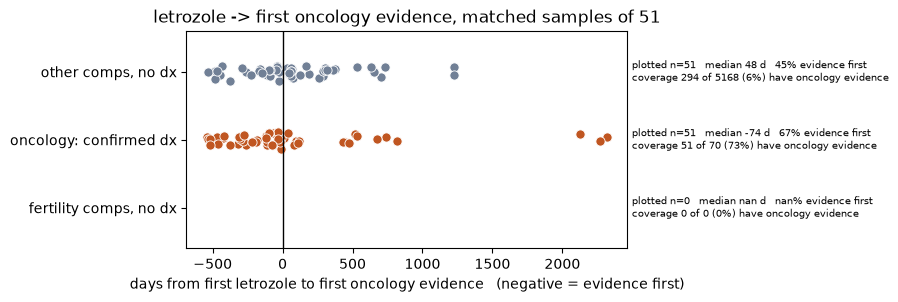

,patients in group,with oncology evidence,coverage %,plotted n,median days,p25,p75,evidence first %
lane,,,,,,,,
"fertility comps, no dx",0,0,0.0,0,NaN,NaN,NaN,NaN
oncology: confirmed dx,70,51,73.0,51,-74.0,-291.0,102.0,67.0
"other comps, no dx",5168,294,6.0,51,48.0,-130.0,296.0,45.0


In [38]:
LANE_NAME = {FERT: 'fertility comps, no dx', ONCO: 'oncology: confirmed dx', BG: 'other comps, no dx'}
onc_first = events[eo.group_mask(events, eo.ONCOLOGY_TAGS)].groupby('person_id').event_date.min()
gap2      = (onc_first - lz).dt.days.dropna()                      # patients with letrozole AND oncology evidence

by_grp = lambda grp: set(grp_of.index[grp_of == grp]) - case_ids
pools  = {FERT: by_grp(FERT), ONCO: case_ids, BG: by_grp(BG)}      # comparison lanes exclude every confirmed-dx patient
have   = {k: sorted(set(gap2.index) & p) for k, p in pools.items()}
N_PLOT = len(have[ONCO])                                           # match the oncology lane's plotted n
rng    = np.random.default_rng(0)
samp   = {k: (have[k] if k == ONCO else sorted(rng.choice(have[k], min(N_PLOT, len(have[k])), replace=False)))
          for k in lanes}

fig, ax = plt.subplots(figsize=(10.5, 3.2))
for y, k in enumerate(lanes):
    d = gap2.loc[samp[k]]
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[k], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"plotted n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} evidence first\n"
                     f"coverage {len(have[k])} of {len(pools[k])} ({len(have[k]) / max(len(pools[k]), 1):.0%}) have oncology evidence",
            transform=ax.get_yaxis_transform(), va='center', fontsize=7.5)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([LANE_NAME[k] for k in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from first letrozole to first oncology evidence   (negative = evidence first)')
ax.set_title(f'letrozole -> first oncology evidence, matched samples of {N_PLOT}')
fig.subplots_adjust(left=.22, right=.64, bottom=.2); plt.show()

rows = []
for k in lanes:
    d = gap2.loc[samp[k]]
    rows.append({'lane': LANE_NAME[k], 'patients in group': len(pools[k]), 'with oncology evidence': len(have[k]),
                 'coverage %': round(len(have[k]) / max(len(pools[k]), 1) * 100, 1), 'plotted n': len(d),
                 'median days': d.median(), 'p25': d.quantile(.25), 'p75': d.quantile(.75),
                 'evidence first %': round((d < 0).mean() * 100, 1)})
display(pd.DataFrame(rows).set_index('lane').round(0))

## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is close to the UI
sketch from the review, but derived from observed transitions rather than a model's guess
about the next event.

In [39]:
import networkx as nx

# every curated codeset tag (codesets.yaml via eo); the raw per-product codes would swamp the graph
FOCUS = set(eo.CODESETS)

# the graph is about curated clinical steps: relabel each concept token by its group, drop uncurated ones, collapse repeats
import itertools
_tg = events.drop_duplicates('tag').dropna(subset=['groups']).set_index('tag')['groups'].astype(str).str.split('|').to_dict()   # token -> ALL its groups
gseqs = {p: [g for g, _ in itertools.groupby(g for t in seqs[p] for g in _tg.get(t, ()))] for p in pids}
Hg = eo.group_loadings(H, events)       # a group's NMF loading = sum over its concept tokens (a token counts in every group it is in)
db_lz_g = [[c for c in gseqs[p] if c in FOCUS] for p in pids if 'letrozole' in gseqs[p]]
print(f"{len(db_lz_g)} letrozole patients")

cnt = collections.Counter()
for s in db_lz_g:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_lz_g))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

# Fill colour = the component group that owns the tag's NMF loading (its share of the tag's total
# loading; fertility is summed over its 4 components). letrozole is the cohort anchor, so it is not in
# the NMF; tags dropped by the prevalence floor are not in H either.
grp_comps = {g: [k for k, v in COMP.items() if v[2] == g] for g in GCOL}
def owner_group(tag):
    if tag == 'letrozole':
        return 'anchor'
    if tag not in Hg.columns or Hg[tag].sum() == 0:
        return 'not in NMF'
    share = {g: Hg.loc[ks, tag].sum() / Hg[tag].sum() for g, ks in grp_comps.items()}
    return max(share, key=share.get)
NODE_COL = {**GCOL, 'anchor': '#f6e05e', 'not in NMF': '#e2e8f0'}
node_grp = {n: owner_group(n) for n in G.nodes()}
print("nodes per group:", dict(collections.Counter(node_grp.values())))


5238 letrozole patients
14 nodes, 90 edges
nodes per group: {'background': 13, 'anchor': 1}


### Trajectory graph on a time axis
x = median days from the first letrozole to the first time the patient has that group (negative = before it), y = the component group that owns the tag's NMF loading. Nodes in a lane are staggered by x, so labels cannot overlap. The cell above only builds the transitions (`G`).

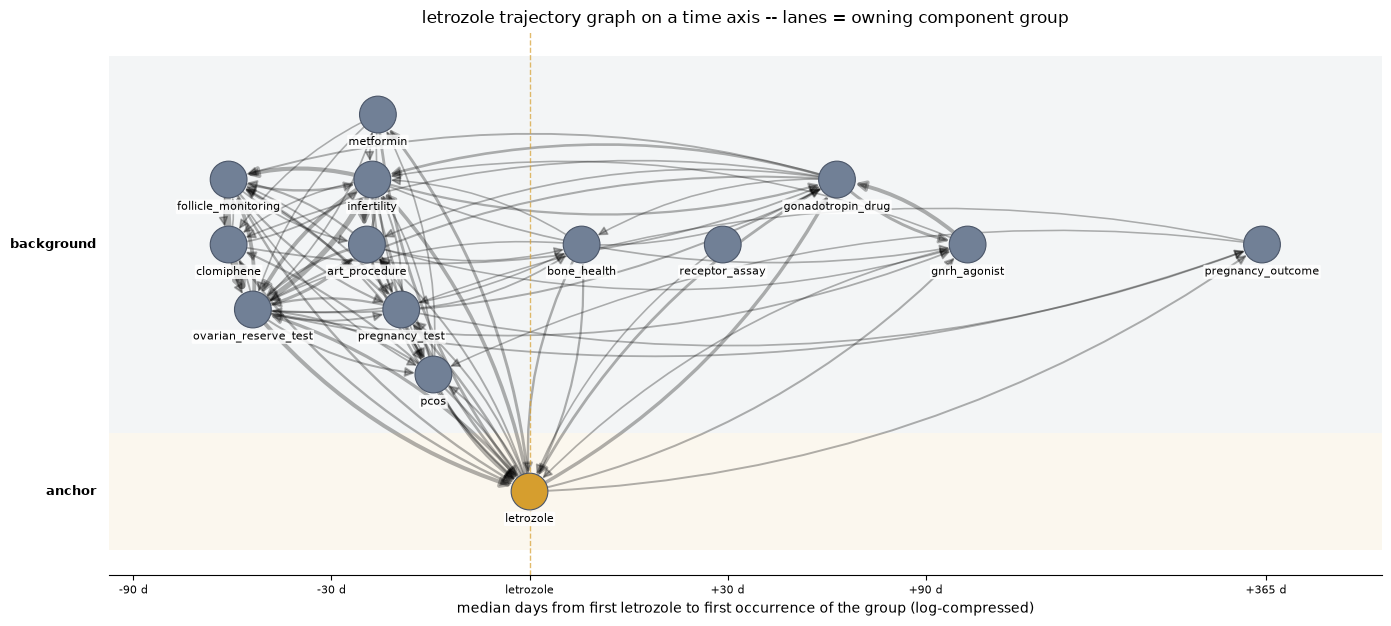

{'background': 13, 'anchor': 1} nodes per lane; 0 without timing


In [40]:
# Trajectory graph on a time axis: x = median days from the patient's first letrozole to the first time the patient has that group
# (log-compressed, 0 = letrozole), y = the component group that owns the tag's NMF loading. Nodes in one lane are staggered by x, so labels cannot overlap.
# Edges are the transitions in G (cell above). Needs the graph cell above and the dated sequences (patseqs) from the hybrid section.
ANCHOR      = 'letrozole'
ANCHOR_NAME = ANCHOR.replace('_', ' ')
MIN_N       = 20                                                   # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                          # vertical stagger step (y units), room one label needs on the x axis (inches)

_nodes  = set(G.nodes())
_have   = [i for i, p in enumerate(pids) if ANCHOR in gseqs[p]]     # the cohort of the graph
_first  = {n: [] for n in _nodes}
_a_tok  = {t for t, gs in _tg.items() if ANCHOR in gs}
for i in _have:
    ps = patseqs[i]
    a0 = min((ps.dpos[t][0] for t in _a_tok if t in ps.dpos), default=None)
    if a0 is None:
        continue
    best = {}
    for t, dl in ps.dpos.items():
        for g in _tg.get(t, ()):
            if g in _nodes and (g not in best or dl[0] < best[g]):
                best[g] = dl[0]
    for g, d in best.items():
        _first[g].append(d - a0)
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
med[ANCHOR] = 0.0

Hg_    = Hg if 'Hg' in globals() else eo.group_loadings(H, events)
comps_ = list(dict.fromkeys(v[2] for v in COMP.values()))           # component groups, in COMP order
def owner_lane(g):
    if g == ANCHOR:
        return 'anchor'
    if g not in Hg_.columns or Hg_[g].sum() == 0:
        return 'not in NMF'
    share = {l: Hg_.loc[[k for k, v in COMP.items() if v[2] == l], g].sum() / Hg_[g].sum() for l in comps_}
    return max(share, key=share.get)
lane_of  = {n: owner_lane(n) for n in _nodes}
LANES    = [l for l in comps_ + ['anchor', 'not in NMF'] if l in set(lane_of.values())]
_pal     = ['#2f855a', '#c05621', '#718096', '#2b6cb0', '#b83280', '#b7791f']
LANE_COL = {**{l: _pal[i % len(_pal)] for i, l in enumerate(comps_)}, 'anchor': '#d69e2e', 'not in NMF': '#a0aec0', **globals().get('GCOL', {})}

tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0           # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                      # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}            # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL.get(l, '#e2e8f0'), alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[LANE_COL.get(lane_of[n], '#e2e8f0') for n in G.nodes()], edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, {n: (x, y - 0.42) for n, (x, y) in pos_t.items()}, ax=ax, font_size=8,
                        bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)              # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else ANCHOR_NAME for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel(f"median days from first {ANCHOR_NAME} to first occurrence of the group (log-compressed)")
ax.set_title(f'{ANCHOR_NAME} trajectory graph on a time axis -- lanes = owning component group')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: int(sum(1 for n in _nodes if lane_of[n] == l)) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")


Read the arms against the NMF components: a fertility-treatment arm (clomiphene,
gonadotropins, ART), a pregnancy arm (pregnancy test, pregnancy outcome), and a much thinner
oncology arm (receptor assay, biopsy, chemotherapy, mastectomy). Whichever dominates numerically
is the answer — let the graph say which, rather than assuming.

**How to read it.** Left to right is time: each tag sits at the median number of days between the patient's first letrozole and the first time they have that tag (log-compressed; left = before letrozole, right = after, the dashed line is letrozole). Each row (lane) is the component group that owns most of the tag's NMF loading (fertility, oncology or other, as grouped in `COMP`). `letrozole` has its own lane because it is the cohort anchor and not in the NMF; a tag too rare to reach the NMF goes to a "not in NMF" lane. Tags inside a lane are staggered up and down only so the labels do not overlap: the vertical offset has no meaning. A tag with fewer than 20 patients who have both it and letrozole has no timing and is parked at the right edge. Positions use the *first* occurrence, so a tag that repeats (labs, drugs) can look earlier than the cycle next to letrozole. A lane is a loading share, not a diagnosis, and a tag shared between groups takes the larger share. Arrows are the observed transitions between consecutive curated steps; thicker = more patients.


## 5 · Final table — top letrozole sequences and where they rank
Per NMF bundle: the highest-lift ordered patterns that contain a letrozole step, each with its rank among the bundle's scored top patterns, and under every top entity the median timing against the first letrozole. A post-filter of the scored candidates, so every score and verdict is the one computed above. Writes its own xlsx.

In [41]:
COHORT = 'letrozole'
# ANCHOR-FOCUSED view of the final table (additional; the table above is untouched): per bundle, the top-TOPK_ANCHOR scored ordered patterns that contain a letrozole step,
# with the position of that step (k of n). Same scores / verdicts as the table above (post-filter of hyb, no re-mining). Own xlsx file; Triage / literature / PMIDs left empty.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"final_table_{COHORT}_k{K}_{VARIANT}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

ANCHOR      = 'letrozole'                                                    # cohort anchor group (codesets.yaml)
ANCHOR_NAME = ANCHOR.replace('_', ' ')
ANCHOR_TOK  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])    # every concept-level token that belongs to the anchor group
TOPK_ANCHOR = 3                                                       # anchor patterns per bundle (highest lift first)

def has_anchor(pattern):
    return any(t in ANCHOR_TOK for t in pattern.split(' -> '))

_a0 = {}
def offset_text(c, members, t, min_n=20):
    """Median days from each patient's first {ANCHOR} step to their first occurrence of token t (negative = t came first), over the bundle's patients who have both."""
    if c not in _a0:                                                       # first anchor day per member, computed once per bundle
        _a0[c] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[c])[~np.isnan(td - _a0[c])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    med = int(np.median(g))
    when = "same day as" if med == 0 else f"{abs(med):,} d {'before' if med < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Re-tests found (of 5)', 'Holds up on re-test?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion (Manual RUW / Routine / Unclear)', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle){offset_text(c, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} explained by " + re.sub(rf"^c{c}: ", "", COMP[c][1]), f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    pool  = hyb.get(c)
    pool  = pool if pool is not None and len(pool) else None
    if pool is not None:
        pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # hyb[c] is lift-sorted
        has  = pool.pattern.map(has_anchor)
    d     = pool[has].head(TOPK_ANCHOR) if pool is not None else None
    head[1] += f"\n{int(has.sum()) if pool is not None else 0} of {len(pool) if pool is not None else 0} scored patterns contain {ANCHOR_NAME}"
    if d is None or not len(d):
        table.append((c, head + ['', f"no scored pattern contains {ANCHOR_NAME} (bundle has {len(pool) if pool is not None else 0} scored patterns)"] + [''] * (len(HEAD) - 5)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        holds = 'Yes' if r.splits_found >= 4 else 'Partly' if r.splits_found == 3 else 'No'
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), int(r.splits_found), holds,
                                                     float(r.lift), r.hybrid_verdict.capitalize(), '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: fused Day 1 + Day 3 notebook, letrozole run ({VARIANT}{', +/- ' + str(WINDOW_MONTHS) + ' months around any letrozole event' if WINDOW_MONTHS else ''}), NMF k={K} on concept-level tokens, {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK_ANCHOR} highest-lift scored ordered patterns of each bundle that contain a {ANCHOR_NAME} step (any {ANCHOR_NAME} concept), from the same candidates as the main table (ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the bundle). The second line of each n (%) cell says how many of the bundle's scored patterns contain {ANCHOR_NAME}.",
    f"Entities: under each entity, the median number of days from the patient's first {ANCHOR_NAME} step to their FIRST occurrence of that entity (before / after), over the bundle patients who have both, and the share of them for whom it came first. Repeated entities (labs, drugs) are read at their first occurrence.",
    "Position among the bundle's scored top patterns: each bundle's candidates are its 100 most frequent ordered patterns (3+ steps) that pass the support floor, scored for lift; the pattern's place in that list by lift (1 = most specific to the bundle) and by support (1 = most frequent), out of the N patterns scored. A bundle with no such pattern is shown as such, not filled.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    "Re-tests: each bundle split in half at random, 5 times; patterns found on one half and checked on the other. Yes = found in 4-5 of 5, Partly = 3, No = 0-2.",
    f"Final verdict = the hybrid verdict: Solid = re-found in >=4 of 5 re-tests with lift range low >= {MIN_LIFT}, downgraded to Suggestive when the family held-out pass rate lower bound is below {HO_MIN_RATE_LO:.0%} ({len(HO_SEEDS)} splits x 2 directions); Suggestive = found in 3 of 5; Unstable otherwise.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/final_table_letrozole_k13_win18.xlsx  (13 bundles, 36 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Position in the bundle's scored top patterns (by lift · by support),Share of group with pattern,Share of everyone else with pattern,Re-tests found (of 5),Holds up on re-test?,Times as common (lift),Final verdict
0,"c0 · c0: catheterization_and, estradiol_total,...",396 (7.6%)\n38 of 100 scored patterns contain ...,1. Catheterization and introduction of… [CPT4 ...,1,Catheterization and introduction of… [CPT4 583...,1 of 100 by lift · 23 of 100 by support,0.462,0.104,5,Yes,4.1,Solid
1,,,,2,Venipuncture for blood test [SNOMED 28520004] ...,3 of 100 by lift · 42 of 100 by support,0.442,0.11,5,Yes,3.8,Solid
2,,,,3,Catheterization and introduction of… [CPT4 583...,4 of 100 by lift · 82 of 100 by support,0.422,0.107,4,Yes,3.7,Solid
3,"c1 · c1: estradiol_2_mg_oral, progesterone_50_...",747 (14.3%)\n61 of 100 scored patterns contain...,1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,5 of 100 by lift · 98 of 100 by support,0.206,0.027,2,No,5.9,Unstable
4,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,6 of 100 by lift · 30 of 100 by support,0.277,0.039,5,Yes,5.8,Solid
5,,,,3,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,9 of 100 by lift · 82 of 100 by support,0.22,0.031,3,Partly,5.6,Suggestive
6,"c2 · c2: amoxicillin_875_mg_c, ibuprofen_800_m...","1,263 (24.1%)\n2 of 2 scored patterns contain ...",1. amoxicillin 875 MG / clavulanate 125… [RxNo...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×3,1 of 2 by lift · 1 of 2 by support,0.393,0.395,0,No,1.0,Unstable
7,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×4,2 of 2 by lift · 2 of 2 by support,0.262,0.257,0,No,1.0,Unstable
8,"c3 · c3: single_live_birth_fr, ultrasound_preg...",541 (10.3%)\n57 of 100 scored patterns contain...,1. Single live birth from singleton… [SNOMED 1...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,2 of 100 by lift · 1 of 100 by support,0.669,0.051,5,Yes,11.2,Solid
9,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,3 of 100 by lift · 96 of 100 by support,0.438,0.033,1,No,10.3,Unstable
